# Test technique Equancy : préparation des données

Ce notebook est la première étape du projet. Il lit les six fichiers fournis, les contrôle, corrige leurs anomalies
et enregistre des fichiers propres dans `data/processed`. Un second notebook construira ensuite le modèle en étoile,
avec une table de faits et deux dimensions, et calculera les indicateurs métier. L'analyse finale sera réalisée
dans Power BI à partir de ces tables.

Chaque fichier suit le même déroulé : présentation des données, lecture et contrôle des types, exploration,
détection des anomalies, correction, puis tests de qualité et sauvegarde. Quand une sortie ne suffit pas
à conclure, on l'approfondit par une analyse ciblée avant de décider d'un traitement. Les fonctions communes
sont regroupées dans la partie 0 et réutilisées d'un fichier à l'autre.

**Plan**

0. Configuration et fonctions communes
1. Émissions de CO₂ par pays
2. Produit intérieur brut (PIB)
3. Indicateurs démographiques
4. Population
5. Dépenses publiques d'éducation
6. Dépenses de préservation du patrimoine

## 0. Configuration et fonctions communes

### 0.1 Configuration

In [23]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

# Dossiers du projet
DOSSIER_BRUT = Path("data/raw")
DOSSIER_PROPRE = Path("data/processed")
DOSSIER_PROPRE.mkdir(parents=True, exist_ok=True)

# Fichiers fournis pour le test
FICHIERS = {
    "emissions": "Emissions per country.csv",
    "pib": "GDP Unesco_fullvalue.csv",
    "demographie": "Demographic indicators.csv",
    "population": "Population (thousands).csv",
    "education": "Governement_Expenditure_education_%_of_GDP.csv",
    "patrimoine": "Expenditure_preservation&conservation.csv",
}

# Lignes qui représentent des regroupements de pays et non des pays
AGREGATS = ["Global", "International Transport"]

Les fonctions qui suivent ne dépendent d'aucun fichier : les noms de colonnes leur sont passés en paramètres.
Les fonctions de lecture, d'exploration et de détection affichent des résultats sans modifier les données.
Les fonctions de conversion et de complétion renvoient un nouveau tableau.

### 0.2 Lecture et contrôle des types

Pour chaque colonne, on mesure la part de valeurs qui peuvent être lues comme des nombres. Une colonne presque entièrement numérique mais lue en texte signale un problème de type à corriger avant l'exploration.

In [24]:
def lire_et_diagnostiquer(nom_fichier, separateur=";"):
    """Lit un fichier CSV, affiche ses dimensions, un aperçu et le contrôle des types. Renvoie le DataFrame."""

    df = pd.read_csv(DOSSIER_BRUT / nom_fichier, sep=separateur, encoding="utf-8-sig")

    print(f"{nom_fichier} : {df.shape[0]:,} lignes x {df.shape[1]} colonnes")
    display(df.head())

    controle = []
    for colonne in df.columns:
        valeurs = df[colonne].dropna().astype(str)
        # La virgule décimale est acceptée pour ne pas confondre "1,5" avec du texte
        en_nombre = pd.to_numeric(valeurs.str.replace(",", ".", regex=False), errors="coerce")
        non_numeriques = valeurs[en_nombre.isna()]

        controle.append({
            "Colonne": colonne,
            "Type lu": str(df[colonne].dtype),
            "% numérique": round(en_nombre.notna().mean() * 100, 1) if len(valeurs) else 0.0,
            "Virgule décimale": "oui" if valeurs.str.contains(",", regex=False)[en_nombre.notna()].any() else "",
            "Exemples non numériques": non_numeriques.unique()[:3].tolist(),
        })

    display(pd.DataFrame(controle).set_index("Colonne"))
    return df

### 0.3 Conversions de types

La première fonction convertit une colonne d'années en entier et retire les lignes où l'année n'est pas un nombre. La seconde convertit des colonnes de valeurs en nombres, en acceptant la virgule décimale.

In [25]:
def convertir_annee(df, col_annee):
    """Convertit la colonne année en entier et retire les lignes où elle n'est pas numérique."""

    annee = pd.to_numeric(df[col_annee], errors="coerce")
    print(f"Lignes retirées (année non numérique) : {annee.isna().sum()}")

    df = df.loc[annee.notna()].copy()
    df[col_annee] = annee[annee.notna()].astype(int)
    return df


def convertir_nombre(df, colonnes):
    """Convertit des colonnes texte en nombres, en acceptant la virgule décimale."""

    df = df.copy()
    for colonne in colonnes:
        df[colonne] = pd.to_numeric(
            df[colonne].astype(str).str.replace(",", ".", regex=False), errors="coerce"
        )
    return df

### 0.4 Fichiers à indicateurs

Certains fichiers rangent un ou plusieurs indicateurs dans une même colonne de valeurs. La première fonction résume le contenu de la colonne des indicateurs. La seconde place chaque indicateur dans sa propre colonne, avec une ligne par pays et par année.

In [26]:
def decrire_indicateurs(df, col_indicateur, col_valeur, col_pays, col_annee):
    """Résume chaque indicateur (volume, couverture, ordre de grandeur) et affiche leur répartition."""

    synthese = df.groupby(col_indicateur).agg(
        lignes=(col_valeur, "size"),
        pays=(col_pays, "nunique"),
        debut=(col_annee, "min"),
        fin=(col_annee, "max"),
        valeur_min=(col_valeur, "min"),
        valeur_mediane=(col_valeur, "median"),
        valeur_max=(col_valeur, "max"),
    )
    display(synthese)

    repartition = df[col_indicateur].value_counts()
    plt.figure(figsize=(9, 1 + len(repartition)))
    plt.barh(repartition.index, repartition.values)
    for position, nombre in enumerate(repartition.values):
        plt.text(nombre, position, f" {nombre} ({nombre / repartition.sum():.0%})", va="center")
    plt.xlabel("Nombre de lignes")
    plt.title("Répartition des lignes par indicateur")
    plt.tight_layout()
    plt.show()


def separer_indicateurs(df, col_indicateur, col_valeur, colonnes_cles, noms_colonnes):
    """Place chaque indicateur dans sa propre colonne, renommée selon noms_colonnes."""

    return (
        df.pivot(index=colonnes_cles, columns=col_indicateur, values=col_valeur)
        .rename(columns=noms_colonnes)
        .reset_index()
        .rename_axis(columns=None)
    )

### 0.5 Exploration

Valeurs manquantes, lignes vides, doublons, couverture, statistiques, valeurs maximales, pays et répartition des valeurs manquantes dans le temps. La couverture compare le nombre de couples pays et année présents au nombre attendu si chaque pays était renseigné chaque année : une année absente n'est pas une valeur vide mais une ligne qui n'existe pas, et elle n'apparaît dans aucun autre contrôle.

In [27]:
def explorer(df, nom, col_pays, col_annee, col_iso=None):
    """Exploration d'un dataset aux types corrigés. Affiche seulement, ne modifie rien."""

    colonnes_valeurs = df.select_dtypes("number").columns.drop(col_annee)
    lignes_vides = df[colonnes_valeurs].isna().all(axis=1)

    # Valeurs manquantes par colonne
    print("Valeurs manquantes par colonne")
    display(pd.DataFrame({
        "Manquants": df.isna().sum(),
        "% manquants": (df.isna().mean() * 100).round(1),
    }).sort_values("% manquants", ascending=False))

    # Lignes vides et doublons
    print(f"Lignes sans aucune valeur : {lignes_vides.sum():,} sur {len(df):,} ({lignes_vides.mean():.1%})")
    print(f"Lignes dupliquées : {df.duplicated().sum()}")
    print(f"Doublons pays + année : {df.duplicated([col_pays, col_annee]).sum()}")

    # Couverture : couples pays et année présents, comparés au nombre attendu
    nb_pays, nb_annees = df[col_pays].nunique(), df[col_annee].nunique()
    couples_presents = len(df[[col_pays, col_annee]].drop_duplicates())
    print(f"\nCouples pays + année attendus ({nb_pays} pays x {nb_annees} années) : {nb_pays * nb_annees:,}")
    print(f"Couples pays + année présents : {couples_presents:,}")
    print(f"Couples pays + année absents : {nb_pays * nb_annees - couples_presents:,}")

    # Statistiques et valeurs maximales, avec le pays et l'année concernés
    print("\nStatistiques des valeurs")
    display(df[colonnes_valeurs].describe().T.round(2))
    print(f"Valeurs négatives : {(df[colonnes_valeurs] < 0).sum().sum()}")

    lignes_max = df.loc[df[colonnes_valeurs].idxmax()]
    maximums = pd.DataFrame({
        "Pays": lignes_max[col_pays].values,
        "Année": lignes_max[col_annee].values,
        "Valeur max": df[colonnes_valeurs].max().round(2).values,
    }, index=colonnes_valeurs)
    print("\nValeur maximale de chaque variable")
    display(maximums)

    # Pays
    print(f"\nPays distincts : {nb_pays}")
    if col_iso:
        print("Pays sans code ISO :", df.loc[df[col_iso].isna(), col_pays].unique().tolist())
    premiere_annee = df[~lignes_vides].groupby(col_pays)[col_annee].min()
    print("Années de première donnée les plus fréquentes (nombre de pays) :")
    display(premiere_annee.value_counts().head(5))

    # Heatmap : part de valeurs manquantes par année et par colonne
    manquants_par_annee = df.drop(columns=col_annee).isna().groupby(df[col_annee]).mean() * 100

    plt.figure(figsize=(13, max(3, 0.5 * manquants_par_annee.shape[1])))
    plt.imshow(manquants_par_annee.T, aspect="auto", cmap="viridis", vmin=0, vmax=100)
    plt.yticks(range(manquants_par_annee.shape[1]), manquants_par_annee.columns)
    pas = max(1, len(manquants_par_annee) // 15)  # environ 15 années affichées
    positions = range(0, len(manquants_par_annee), pas)
    plt.xticks(positions, [str(manquants_par_annee.index[i]) for i in positions], rotation=45)
    plt.colorbar(label="Valeurs manquantes (%)")
    plt.title(f"Valeurs manquantes par année : {nom}")
    plt.xlabel("Année")
    plt.tight_layout()
    plt.show()

### 0.6 Détection des anomalies

Cohérence entre codes ISO et pays, valeurs nulles, valeurs manquantes restantes, années absentes au milieu des séries, séries qui commencent tard ou s'arrêtent tôt, variations brutales d'une année sur l'autre et valeurs les plus élevées. La fonction analyse une variable cible à la fois. Le seuil de variation vaut 100 % par défaut et s'abaisse pour une variable qui évolue lentement, comme une population.

In [28]:
def detecter_anomalies(df, colonnes_valeurs, col_cible, col_pays, col_annee, col_iso, seuil_variation=1):
    """Recherche les anomalies sur une variable cible. Affiche seulement, ne modifie rien.
    seuil_variation : variation annuelle à partir de laquelle on signale un saut (1 = 100 %)."""

    df = df.sort_values([col_pays, col_annee])

    # Unicité du lien entre code ISO et pays
    print(f"Codes ISO partagés par plusieurs pays : {(df.groupby(col_iso)[col_pays].nunique() > 1).sum()}")
    print(f"Pays avec plusieurs codes ISO : {(df.groupby(col_pays)[col_iso].nunique() > 1).sum()}")

    # Valeurs nulles sur la variable cible
    zeros = df[df[col_cible] == 0]
    print(f"\nLignes où {col_cible} vaut 0 : {len(zeros)}")
    display(zeros.groupby(col_pays)[col_annee].agg(["count", "min", "max"])
            .sort_values("count", ascending=False).head(10))

    # Valeurs manquantes restantes, colonne par colonne
    print(f"Lignes avec au moins une valeur manquante : {df[colonnes_valeurs].isna().any(axis=1).sum()}")
    display(df[colonnes_valeurs].isna().sum().to_frame("Manquants"))

    # Années absentes au milieu d'une série (la ligne affichée est l'année qui suit le trou)
    ecart = df.groupby(col_pays)[col_annee].diff()
    trous = df.loc[ecart > 1, [col_pays, col_annee]].assign(annees_absentes=ecart[ecart > 1] - 1)
    print(f"Pays avec des années absentes au milieu de leur série : {trous[col_pays].nunique()}")
    display(trous)

    # Séries qui commencent après la première année du fichier ou s'arrêtent avant la dernière
    couverture = df.groupby(col_pays)[col_annee].agg(debut="min", fin="max")
    incompletes = couverture[(couverture["debut"] > df[col_annee].min()) | (couverture["fin"] < df[col_annee].max())]
    print(f"Pays dont la série commence tard ou s'arrête tôt : {len(incompletes)}")
    display(incompletes.sort_values("debut", ascending=False))

    # Variations brutales d'une année sur l'autre (hors très petites valeurs)
    variation = df.groupby(col_pays)[col_cible].pct_change(fill_method=None)
    sauts = df[(variation.abs() > seuil_variation) & (df[col_cible] > 1)]
    print(f"Variations annuelles de plus de {seuil_variation:.0%} : {len(sauts)} dans {sauts[col_pays].nunique()} pays")
    display(sauts[col_pays].value_counts().head(10))

    # Pic de chaque pays, en ignorant les pays sans aucune valeur, puis les dix plus élevés
    renseignes = df.dropna(subset=[col_cible])
    pics = renseignes.loc[renseignes.groupby(col_pays)[col_cible].idxmax()]
    print("Les 10 pays au pic le plus élevé")
    display(pics.nlargest(10, col_cible)[[col_pays, col_annee, col_cible]])

### 0.7 Complétion des années absentes

Une année absente n'est reconstituée que si elle se trouve au milieu d'une série, dans un trou de deux ans au plus, entre deux valeurs connues. Les trous plus longs et les années situées avant le début ou après la fin d'une série ne sont pas modifiés, car il n'existe pas de valeur des deux côtés pour encadrer l'estimation.

In [29]:
def completer_annees(df, colonnes_valeurs, col_pays, col_annee, col_iso, trou_max=2):
    """Ajoute les années absentes au milieu d'une série quand le trou fait au plus trou_max ans,
    puis interpole toutes les valeurs manquantes situées entre deux valeurs connues."""

    df = df.sort_values([col_pays, col_annee])
    ordre_colonnes = df.columns

    series = []
    for pays, serie in df.groupby(col_pays):
        plus_grand_ecart = serie[col_annee].diff().max()
        if 1 < plus_grand_ecart <= trou_max + 1:
            annees = range(serie[col_annee].min(), serie[col_annee].max() + 1)
            serie = serie.set_index(col_annee).reindex(annees).rename_axis(col_annee).reset_index()
            serie[col_pays] = pays
            serie[col_iso] = serie[col_iso].ffill()
        series.append(serie)
    df = pd.concat(series, ignore_index=True)

    # Interpolation linéaire, seulement entre deux valeurs connues
    print(f"Lignes interpolées : {df[colonnes_valeurs].isna().any(axis=1).sum()}")
    df[colonnes_valeurs] = df.groupby(col_pays)[colonnes_valeurs].transform(
        lambda serie: serie.interpolate(limit=trou_max, limit_area="inside")
    )
    return df[ordre_colonnes].reset_index(drop=True)

### 0.8 Tests de qualité

Chaque règle renvoie OK ou KO, et la cellule s'arrête si l'une d'elles échoue : aucune donnée non conforme ne passe à l'étape suivante. Quand des valeurs manquantes sont assumées, par exemple un indicateur qui n'est pas publié pour une année, on vérifie seulement qu'aucune ligne n'est entièrement vide.

In [30]:
def tester_qualite(df, colonnes_valeurs, col_pays, col_annee, col_iso, periode, col_total=None,
                   manquants_autorises=False):
    """Vérifie les règles de qualité et s'arrête si l'une d'elles n'est pas respectée."""

    toutes_valeurs = colonnes_valeurs + ([col_total] if col_total else [])
    regles = {
        "Année au format entier": pd.api.types.is_integer_dtype(df[col_annee]),
        f"Années comprises entre {periode[0]} et {periode[1]}": df[col_annee].between(*periode).all(),
        "Aucun doublon pays + année": not df.duplicated([col_pays, col_annee]).any(),
        "Un seul pays par code ISO": (df.groupby(col_iso)[col_pays].nunique() == 1).all(),
        "Aucun code ISO manquant": df[col_iso].notna().all(),
        "Aucune valeur négative": not (df[toutes_valeurs] < 0).any().any(),
        "Agrégats retirés": not df[col_pays].isin(AGREGATS).any(),
    }
    if manquants_autorises:
        regles["Aucune ligne entièrement vide"] = not df[toutes_valeurs].isna().all(axis=1).any()
    else:
        regles["Aucune valeur manquante"] = df[toutes_valeurs].notna().all().all()
    if col_total:
        regles["Aucun total nul"] = (df[col_total] > 0).all()
        regles["Total égal à la somme des sources"] = (
            (df[colonnes_valeurs].sum(axis=1) - df[col_total]).abs().max() < 1e-9
        )

    resultat = pd.Series({regle: "OK" if valide else "KO" for regle, valide in regles.items()},
                         name="Résultat")
    display(resultat.to_frame())

    echecs = resultat[resultat == "KO"].index.tolist()
    assert not echecs, f"Règles non respectées : {echecs}"
    print(f"Les {len(regles)} règles sont respectées.")

## 1. Émissions de CO₂ par pays

Ce fichier mesure les émissions de dioxyde de carbone (CO₂) d'origine fossile, c'est-à-dire liées à la combustion
du charbon (Coal), du pétrole (Oil) et du gaz (Gas), à la production de ciment (Cement), au torchage du gaz
sur les sites pétroliers (Flaring) et à d'autres sources industrielles (Other). Les valeurs sont exprimées
en tonnes de CO₂ par habitant, pour chaque pays et chaque année de 1750 à 2021. C'est la variable centrale de l'étude :
les autres fichiers serviront à l'expliquer.

| Colonne | Signification |
|---|---|
| Country | Nom du pays ou de l'entité |
| ISO 3166-1 alpha-3 | Code ISO du pays à trois lettres, clé de jointure avec les autres fichiers |
| Year | Année de la mesure |
| Coal, Oil, Gas, Cement, Flaring, Other | Émissions par source, en tonnes de CO₂ par habitant |

### 1.1 Lecture et contrôle des types

In [31]:
df_emissions = lire_et_diagnostiquer(FICHIERS["emissions"])

Emissions per country.csv : 63,104 lignes x 9 colonnes


,Country,ISO 3166-1 alpha-3,Year,Coal,Oil,Gas,Cement,Flaring,Other
0,Afghanistan,AFG,1750,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,AFG,1751,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,1752,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,1753,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,1754,NaN,NaN,NaN,NaN,NaN,NaN


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
Country,str,0.0,,"[Afghanistan, Albania, Algeria]"
ISO 3166-1 alpha-3,str,0.0,,"[AFG, ALB, DZA]"
Year,str,99.6,,[BES]
Coal,float64,100.0,,[]
Oil,float64,100.0,,[]
Gas,float64,100.0,,[]
Cement,float64,100.0,,[]
Flaring,float64,100.0,,[]
Other,float64,100.0,,[]


Le fichier compte 63 104 lignes et 9 colonnes. Les six sources d'émissions sont bien lues comme des nombres
décimaux, mais Year est lue en texte alors qu'elle est numérique à 99,6 %. La seule valeur en cause est « BES ».

In [32]:
display(df_emissions[df_emissions["Year"] == "BES"].head())

,Country,ISO 3166-1 alpha-3,Year,Coal,Oil,Gas,Cement,Flaring,Other
6528,Bonaire,Saint Eustatius and Saba,BES,NaN,NaN,NaN,NaN,NaN,NaN
6529,Bonaire,Saint Eustatius and Saba,BES,NaN,NaN,NaN,NaN,NaN,NaN
6530,Bonaire,Saint Eustatius and Saba,BES,NaN,NaN,NaN,NaN,NaN,NaN
6531,Bonaire,Saint Eustatius and Saba,BES,NaN,NaN,NaN,NaN,NaN,NaN
6532,Bonaire,Saint Eustatius and Saba,BES,NaN,NaN,NaN,NaN,NaN,NaN


Les 272 lignes concernées correspondent toutes au territoire « Bonaire, Saint Eustatius and Saba »
(Pays-Bas caribéens, code ISO BES). Dans le fichier source, son nom contient un point-virgule, qui est aussi
le séparateur : les colonnes sont décalées et l'année n'apparaît pas. Sur ces 272 lignes, 72 contiennent
des émissions, mais on ne peut pas les situer dans le temps. Ce territoire de quelques dizaines de milliers
d'habitants n'a pas d'effet sur l'analyse : on retire ces lignes et on convertit Year en entier.

In [33]:
df_emissions = convertir_annee(df_emissions, col_annee="Year")

Lignes retirées (année non numérique) : 272


### 1.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
Other,61212,97.4
Cement,47456,75.5
Flaring,45960,73.1
Gas,45892,73.0
Oil,45865,73.0
Coal,45766,72.8
ISO 3166-1 alpha-3,1632,2.6
Country,0,0.0
Year,0,0.0


Lignes sans aucune valeur : 45,607 sur 62,832 (72.6%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (231 pays x 272 années) : 62,832
Couples pays + année présents : 62,832
Couples pays + année absents : 0

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Coal,17066.0,1.13,2.45,0.0,0.00,0.04,1.10,34.23
Oil,16967.0,2.78,17.61,0.0,0.13,0.75,2.61,834.19
Gas,16940.0,0.68,2.69,0.0,0.00,0.00,0.19,53.31
Cement,15376.0,0.08,0.14,0.0,0.00,0.03,0.12,2.57
Flaring,16872.0,0.22,2.77,0.0,0.00,0.00,0.00,113.26
Other,1620.0,0.09,0.06,0.0,0.04,0.07,0.12,0.35


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Coal,Luxembourg,1960,34.23
Oil,Sint Maarten (Dutch part),1954,834.19
Gas,Qatar,1993,53.31
Cement,Bahamas,1972,2.57
Flaring,Qatar,1963,113.26
Other,Belarus,1990,0.35



Pays distincts : 231
Pays sans code ISO : ['French Equatorial Africa', 'French West Africa', 'Kuwaiti Oil Fires', 'Leeward Islands', 'Pacific Islands (Palau)', 'Ryukyu Islands']
Années de première donnée les plus fréquentes (nombre de pays) :


Year
1950    151
1990      8
1959      7
1820      6
1958      4
Name: count, dtype: int64

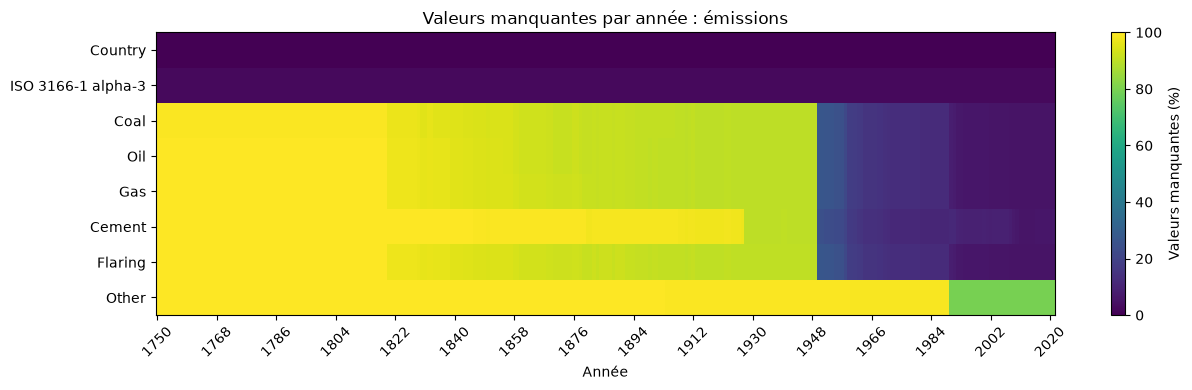

In [34]:
explorer(df_emissions, "émissions", col_pays="Country", col_annee="Year", col_iso="ISO 3166-1 alpha-3")

Country et Year sont complètes. Les sources d'émissions ont entre 73 et 75 % de valeurs manquantes, et Other
atteint 97,4 %. Ce n'est pas un problème de saisie : près de 73 % des lignes n'ont aucune valeur, car le fichier
contient une ligne par pays et par année depuis 1750, même quand rien n'était mesuré. Pour la même raison,
aucun couple pays et année n'est absent du fichier.

Le code ISO manque sur 1 632 lignes, soit exactement 6 entités sur 272 années : cinq territoires qui n'existent
plus (French West Africa, French Equatorial Africa, Leeward Islands, Ryukyu Islands, Pacific Islands (Palau))
et un événement, les incendies de puits du Koweït en 1991 (Kuwaiti Oil Fires). Aucune de ces entités n'a
d'émission renseignée, elles disparaîtront avec les lignes vides.

Il n'y a aucun doublon, ni sur les lignes entières ni sur le couple pays et année. Les 199 doublons qu'on obtenait
avant la correction de Year venaient tous des lignes de Bonaire, devenues identiques une fois l'année perdue.

Aucune valeur n'est négative. L'unité se vérifie sur quelques pays : en 2021, la somme des sources donne 14,9 t/hab
pour les États-Unis et 4,7 pour la France, ce qui correspond aux chiffres publiés. Les distributions sont très
asymétriques (pour Oil, une médiane de 0,75 pour un maximum de 834), et les maximums viennent de petits pays comme
Sint Maarten, le Qatar ou le Luxembourg. On y revient lors de la détection des anomalies.

Le fichier compte 231 entités, dont deux agrégats : Global, qui représente le monde, et International Transport,
le transport aérien et maritime international. La heatmap montre qu'avant 1820 presque rien n'est mesuré et que,
jusqu'en 1949, seuls quelques pays industrialisés sont suivis. La rupture a lieu en 1950, année de la première
donnée pour 151 pays, et les valeurs manquantes passent sous les 10 % à partir de 1990.

### 1.3 Préparation

On fixe une règle simple pour les variables : au-delà de 90 % de valeurs manquantes, une variable apporte trop peu
d'information et elle est retirée. C'est le cas de Other, renseignée pour 47 pays seulement depuis 1990 et qui pèse
environ 0,04 t/hab au niveau mondial. On retire ensuite les lignes sans aucune valeur, puis on limite l'étude
à la période 1950 à 2021, où la majorité des pays est couverte. On ajoute enfin une colonne Total, absente du fichier.
Global est mis de côté pour servir de référence mondiale, et International Transport est retiré des analyses par pays.

La corrélation entre les sources a aussi été regardée : elle est faible, au maximum 0,37, et n'apporte pas
d'information utile pour l'étude.

In [35]:
SOURCES = ["Coal", "Oil", "Gas", "Cement", "Flaring"]   # Other est retirée


def preparer_emissions(df):
    """Applique les choix de préparation. Renvoie le tableau des pays et la série mondiale."""

    print(f"Départ : {len(df):,} lignes")

    df = df.drop(columns="Other")

    df = df.dropna(subset=SOURCES, how="all")
    print(f"Après retrait des lignes vides : {len(df):,} lignes")

    df = df[df["Year"].between(1950, 2021)].copy()
    print(f"Après restriction à 1950-2021 : {len(df):,} lignes")

    df["Total"] = df[SOURCES].sum(axis=1)

    df_monde = df[df["Country"] == "Global"].reset_index(drop=True)
    df_pays = df[~df["Country"].isin(AGREGATS)].reset_index(drop=True)
    print(f"Pays : {len(df_pays):,} lignes pour {df_pays['Country'].nunique()} pays | Monde : {len(df_monde)} années")

    return df_pays, df_monde


df_emissions_pays, df_emissions_monde = preparer_emissions(df_emissions)

Départ : 62,832 lignes
Après retrait des lignes vides : 17,225 lignes
Après restriction à 1950-2021 : 14,837 lignes
Pays : 14,765 lignes pour 218 pays | Monde : 72 années


### 1.4 Détection des anomalies

In [36]:
detecter_anomalies(df_emissions_pays, colonnes_valeurs=SOURCES, col_cible="Total",
                   col_pays="Country", col_annee="Year", col_iso="ISO 3166-1 alpha-3")

Codes ISO partagés par plusieurs pays : 0
Pays avec plusieurs codes ISO : 0

Lignes où Total vaut 0 : 157


,count,min,max
Country,,,
Andorra,40,1950,1989
Mayotte,40,1950,1989
Tuvalu,40,1950,1989
Mauritania,9,1950,1958
Côte d'Ivoire,8,1950,1957
Guinea,8,1950,1957
Cambodia,5,1950,1954
Kuwait,2,1952,1953
Eritrea,2,1990,1993


Lignes avec au moins une valeur manquante : 334


,Manquants
Coal,153
Oil,153
Gas,153
Cement,181
Flaring,153


Pays avec des années absentes au milieu de leur série : 3


...

,debut,fin
Country,,
Kosovo,2008,2021
Timor-Leste,2002,2021
Micronesia (Federated States of),1992,2021
Marshall Islands,1992,2021
Palau,1992,2021
Eritrea,1990,2021
Lesotho,1990,2021
Namibia,1990,2021
Anguilla,1990,2021


Variations annuelles de plus de 100% : 54 dans 33 pays


Country
Aruba                        4
Curaçao                      4
Antigua and Barbuda          3
Niue                         3
Sint Maarten (Dutch part)    3
Cook Islands                 2
Equatorial Guinea            2
Greenland                    2
Libya                        2
Montserrat                   2
Name: count, dtype: int64

Les 10 pays au pic le plus élevé


,Country,Year,Total
11307,Sint Maarten (Dutch part),1954,834.192642
10482,Qatar,1963,120.383434
3146,Curaçao,1956,118.296711
13900,United Arab Emirates,1969,80.973415
6947,Kuwait,1965,68.874700
1858,Brunei Darussalam,1973,66.906437
916,Bahamas,1977,46.114587
7591,Luxembourg,1974,41.048885
13414,Trinidad and Tobago,2010,33.296140
658,Aruba,2007,29.149369


Chaque code ISO correspond à un seul pays et chaque pays à un seul code : la colonne ISO pourra servir de clé
de jointure avec les autres fichiers.

La sortie fait apparaître 157 totaux nuls, ce qui est surprenant puisque aucune valeur n'est négative : un total nul
voudrait dire qu'aucune source n'émet. On regarde ces lignes de plus près, en distinguant celles où les sources
sont vides de celles où elles valent réellement 0. Cement est exclu de ce test, car il vaut 0 par défaut sur ces lignes.

In [37]:
totaux_nuls = df_emissions_pays[df_emissions_pays["Total"] == 0]
non_mesure = totaux_nuls[["Coal", "Oil", "Gas", "Flaring"]].isna().all(axis=1)
print(f"Totaux nuls dont les sources sont vides : {non_mesure.sum()} | sources réellement à 0 : {(~non_mesure).sum()}")

# Lignes non mesurées : la période de zéros s'arrête-t-elle juste avant la première vraie mesure ?
periode_nulle = totaux_nuls[non_mesure].groupby("Country")["Year"].agg(["count", "min", "max"])
periode_nulle["premiere_mesure"] = (
    df_emissions_pays[df_emissions_pays["Total"] > 0].groupby("Country")["Year"].min()
)
display(periode_nulle)

# Zéros saisis explicitement
display(totaux_nuls[~non_mesure])

Totaux nuls dont les sources sont vides : 153 | sources réellement à 0 : 4


,count,min,max,premiere_mesure
Country,,,,
Andorra,40,1950,1989,1990
Cambodia,5,1950,1954,1955
Côte d'Ivoire,8,1950,1957,1958
Eritrea,2,1990,1993,1994
Guinea,8,1950,1957,1958
Mauritania,9,1950,1958,1959
Mayotte,40,1950,1989,1990
Namibia,1,1990,1990,1991
Tuvalu,40,1950,1989,1990


,Country,ISO 3166-1 alpha-3,Year,Coal,Oil,Gas,Cement,Flaring,Total
6934,Kuwait,KWT,1952,0.0,0.0,0.0,0.0,0.0,0.0
6935,Kuwait,KWT,1953,0.0,0.0,0.0,0.0,0.0,0.0
11519,Saudi Arabia,SAU,1951,0.0,0.0,0.0,NaN,0.0,0.0
11520,Saudi Arabia,SAU,1952,0.0,0.0,0.0,NaN,0.0,0.0


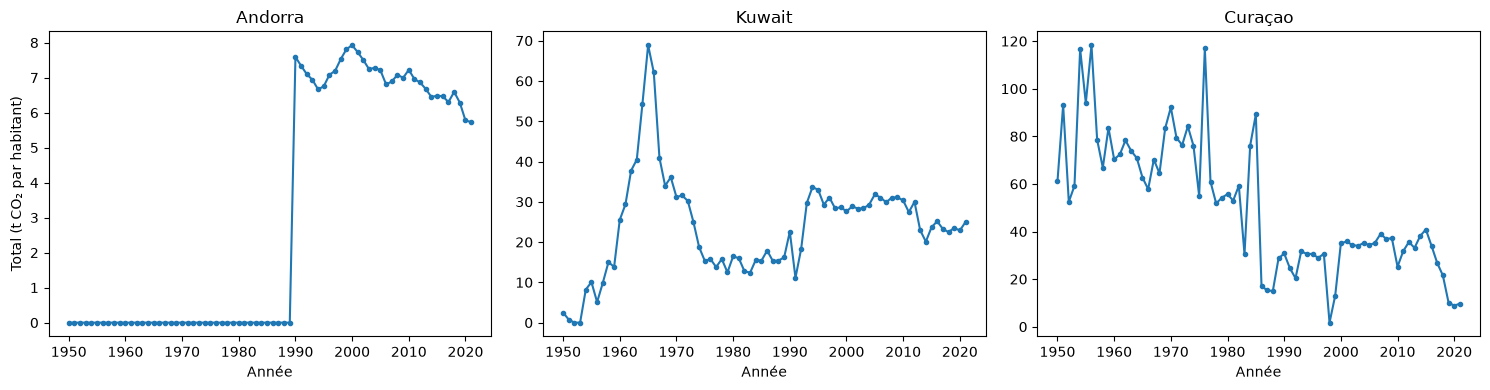

In [38]:
# Évolution du Total pour trois cas typiques
exemples = ["Andorra", "Kuwait", "Curaçao"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, pays in zip(axes, exemples):
    serie = df_emissions_pays[df_emissions_pays["Country"] == pays]
    ax.plot(serie["Year"], serie["Total"], marker=".")
    ax.set_title(pays)
    ax.set_xlabel("Année")
axes[0].set_ylabel("Total (t CO₂ par habitant)")
plt.tight_layout()
plt.show()

Dans 153 cas, Coal, Oil, Gas et Flaring sont vides et seul Cement vaut 0 : le total nul vient d'une somme de valeurs
manquantes. Ces lignes concernent 9 pays, dont Andorre, Mayotte et Tuvalu de 1950 à 1989, et dans tous les cas
la période de zéros s'arrête exactement l'année qui précède la première vraie mesure. Ces pays n'étaient simplement
pas encore mesurés, comme le montre la courbe d'Andorre. Les 4 autres lignes (Koweït en 1952 et 1953, Arabie saoudite
en 1951 et 1952) ont des sources explicitement à 0, mais au milieu d'une série remplie : le Koweït passe de 0,74 à 0,
puis à 8,2 t/hab, ce qui n'est pas crédible pour un pays pétrolier. Il s'agit de valeurs manquantes saisies
comme des zéros.

En dehors de ces 153 lignes, 181 lignes n'ont que Cement de manquant (Macao, Somalie, Tchad, Guyana, etc.) :
ce sont des pays sans production de ciment.

Trois pays ont des années absentes au milieu de leur série. Le trou de l'Érythrée disparaîtra avec les lignes
non mesurées. Il manque 2 ans au Swaziland, ce qui peut être interpolé, et 12 ans à Sainte-Hélène, ce qui est trop long
pour être reconstitué ; ses émissions sont négligeables et le trou est laissé tel quel. Aucune série ne s'arrête
avant 2021, mais 45 pays commencent après 1950. Ce sont surtout des pays devenus indépendants ou mesurés plus tard,
comme le Kosovo (2008), le Timor oriental (2002) ou l'Érythrée (1990) : leurs années antérieures ne sont pas
reconstituées.

On relève 54 variations de plus de 100 % dans 33 pays, presque tous de petites îles dotées d'une raffinerie, comme
Aruba, Curaçao ou Sint Maarten. La courbe de Curaçao est très irrégulière mais cohérente : elle suit l'activité
de la raffinerie rapportée à une très petite population. Ces valeurs sont réelles.

Sint Maarten arrive en tête des valeurs les plus élevées avec 834 t/hab en 1954, loin devant le Qatar (120),
Curaçao (118), les Émirats arabes unis (81) et le Koweït (69). Ce sont des pays pétroliers et de petites îles,
où le moindre volume d'émissions donne un chiffre par habitant très élevé. Ces valeurs sont conservées ;
pour les classements par habitant, on ne retiendra que les pays de plus d'un million d'habitants.

### 1.5 Correction des anomalies

On supprime les lignes non mesurées, on remplace les zéros saisis à tort par des valeurs manquantes et le Cement
manquant par 0, puis on complète et on interpole les trous de 2 ans au plus. Les variations brutales et les valeurs
extrêmes, réelles, ne sont pas modifiées.

In [39]:
def corriger_emissions(df):
    """Corrige les anomalies détectées sur le tableau des pays. Renvoie un nouveau DataFrame."""

    df = df.copy()
    print(f"Départ : {len(df):,} lignes")

    # Lignes non mesurées : sources vides et Cement à 0 par défaut
    non_mesure = df[["Coal", "Oil", "Gas", "Flaring"]].isna().all(axis=1)
    df = df[~non_mesure]
    print(f"Lignes non mesurées supprimées : {non_mesure.sum()}")

    # Zéros saisis au milieu d'une série : remplacés par des valeurs manquantes, interpolées plus bas
    faux_zeros = df[SOURCES].sum(axis=1) == 0
    df.loc[faux_zeros, ["Coal", "Oil", "Gas", "Flaring"]] = None
    print(f"Zéros remplacés par des valeurs manquantes : {faux_zeros.sum()}")

    # Pays sans production de ciment
    print(f"Cement manquant remplacé par 0 : {df['Cement'].isna().sum()}")
    df["Cement"] = df["Cement"].fillna(0)

    # Trous de 2 ans au plus et zéros remplacés : complétés par interpolation
    df = completer_annees(df, colonnes_valeurs=SOURCES, col_pays="Country",
                          col_annee="Year", col_iso="ISO 3166-1 alpha-3")

    df["Total"] = df[SOURCES].sum(axis=1)
    print(f"Arrivée : {len(df):,} lignes pour {df['Country'].nunique()} pays")
    return df


df_emissions_pays = corriger_emissions(df_emissions_pays)

Départ : 14,765 lignes
Lignes non mesurées supprimées : 153
Zéros remplacés par des valeurs manquantes : 4
Cement manquant remplacé par 0 : 181
Lignes interpolées : 6
Arrivée : 14,614 lignes pour 218 pays


Six lignes sont interpolées : les quatre zéros saisis à tort et les deux années ajoutées pour le Swaziland.
Le Koweït passe ainsi de 0,74 en 1951 à 3,23 puis 5,72, avant d'atteindre 8,2 en 1954 : la progression est cohérente.
Le trou de l'Érythrée a disparu avec les lignes non mesurées, sa série commence désormais en 1994.

### 1.6 Tests de qualité et sauvegarde

In [40]:
tester_qualite(df_emissions_pays, colonnes_valeurs=SOURCES, col_pays="Country", col_annee="Year",
               col_iso="ISO 3166-1 alpha-3", periode=(1950, 2021), col_total="Total")

df_emissions_pays.to_csv(DOSSIER_PROPRE / "emissions_pays.csv", index=False)
df_emissions_monde.to_csv(DOSSIER_PROPRE / "emissions_monde.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 1950 et 2021,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune valeur manquante,OK
Aucun total nul,OK
Total égal à la somme des sources,OK


Les 10 règles sont respectées.


Le fichier des émissions est prêt : 14 614 lignes pour 218 pays de 1950 à 2021, sans valeur manquante
ni anomalie non expliquée, avec une série mondiale de 72 années pour servir de référence. Seul le trou
de Sainte-Hélène est conservé, volontairement.

## 2. Produit intérieur brut (PIB)

Le PIB mesure la valeur de l'ensemble des biens et services produits dans un pays au cours d'une année.
C'est l'indicateur le plus courant de la taille d'une économie. Le fichier donne le PIB de chaque pays de 2000 à 2021,
en dollars américains courants, c'est-à-dire aux prix de chaque année et sans correction de l'inflation.
Dans l'étude, il permettra de mesurer la croissance des pays et de rapporter les émissions à leur niveau de richesse.

| Colonne | Signification |
|---|---|
| LOCATION | Code ISO du pays à trois lettres |
| Country | Nom du pays |
| Time | Année de la mesure |
| Value | PIB en dollars américains courants |

### 2.1 Lecture et contrôle des types

In [41]:
df_pib = lire_et_diagnostiquer(FICHIERS["pib"])

GDP Unesco_fullvalue.csv : 4,539 lignes x 4 colonnes


,LOCATION,Country,Time,Value
0,AUS,Australia,2000,"416000000000,00"
1,AUS,Australia,2001,"379000000000,00"
2,AUS,Australia,2002,"396000000000,00"
3,AUS,Australia,2003,"467000000000,00"
4,AUS,Australia,2004,"614000000000,00"


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
LOCATION,str,0.0,,"[AUS, AUT, BEL]"
Country,str,0.0,,"[Australia, Austria, Belgium]"
Time,int64,100.0,,[]
Value,str,100.0,oui,[]


Le fichier compte 4 539 lignes et 4 colonnes. Time est déjà lue comme un entier, mais Value est lue en texte :
elle est entièrement numérique, avec une virgule comme séparateur décimal (416000000000,00). On la convertit
en nombre décimal.

In [42]:
df_pib = convertir_nombre(df_pib, ["Value"])

### 2.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
LOCATION,0,0.0
Country,0,0.0
Time,0,0.0
Value,0,0.0


Lignes sans aucune valeur : 0 sur 4,539 (0.0%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (213 pays x 22 années) : 4,686
Couples pays + année présents : 4,539
Couples pays + année absents : 147

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Value,4539.0,3.121902e+11,1.397643e+12,13965036.0,4.150012e+09,1.775989e+10,1.210000e+11,2.330000e+13


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Value,United States of America,2021,2.330000e+13



Pays distincts : 213
Pays sans code ISO : []
Années de première donnée les plus fréquentes (nombre de pays) :


Time
2000    199
2002      5
2011      3
2001      2
2006      1
Name: count, dtype: int64

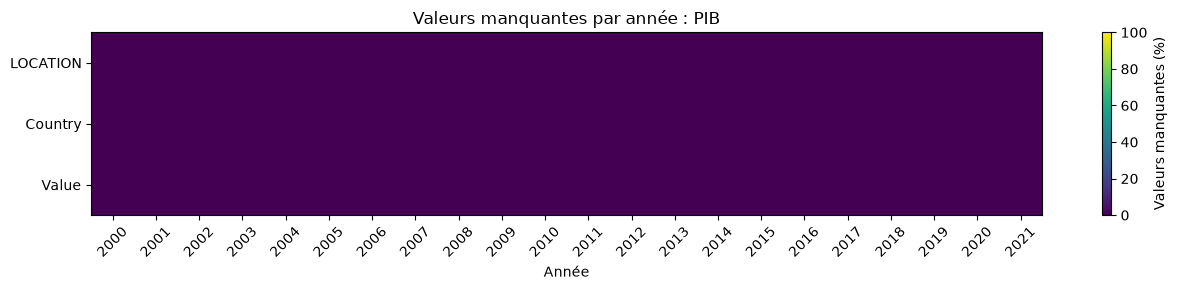

In [43]:
explorer(df_pib, "PIB", col_pays="Country", col_annee="Time", col_iso="LOCATION")

Le fichier ne contient aucune valeur manquante, aucun doublon et aucune valeur négative ou nulle. Il couvre 213 pays
de 2000 à 2021, et chaque pays a un code ISO. L'unité se vérifie sur les États-Unis, qui atteignent 23 300 milliards
de dollars en 2021, ce qui correspond aux chiffres publiés.

La couverture n'est pourtant pas complète : 4 686 couples pays et année sont attendus, mais 4 539 seulement sont
présents, soit 147 années absentes. Seuls 199 pays commencent en 2000. Ces années absentes n'apparaissent pas
comme des valeurs manquantes, car les lignes correspondantes n'existent pas ; la détection des anomalies montre
quels pays sont concernés.

Environ 28 % des valeurs, surtout parmi les plus élevées, sont arrondies à trois chiffres significatifs
(416 000 000 000 pour l'Australie en 2000). Cette précision suffit largement pour l'analyse.

### 2.3 Détection des anomalies

In [44]:
detecter_anomalies(df_pib, colonnes_valeurs=["Value"], col_cible="Value",
                   col_pays="Country", col_annee="Time", col_iso="LOCATION")

Codes ISO partagés par plusieurs pays : 0
Pays avec plusieurs codes ISO : 0

Lignes où Value vaut 0 : 0


,count,min,max
Country,,,


Lignes avec au moins une valeur manquante : 0


,Manquants
Value,0


Pays avec des années absentes au milieu de leur série : 1


...

,debut,fin
Country,,
Somalia,2013,2021
Curaçao,2011,2021
Sint Maarten (Dutch part),2011,2018
Saint-Martin (French part),2011,2014
Nauru,2010,2021
South Sudan,2008,2015
Cayman Islands,2006,2021
American Samoa,2002,2021
Guam,2002,2021


Variations annuelles de plus de 100% : 3 dans 3 pays


Country
Guyana      1
Malawi      1
Zimbabwe    1
Name: count, dtype: int64

Les 10 pays au pic le plus élevé


,Country,Time,Value
4125,United States of America,2021,2.330000e+13
1267,China,2021,1.770000e+13
320,Japan,2012,6.270000e+12
197,Germany,2021,4.260000e+12
2047,India,2021,3.180000e+12
3724,United Kingdom of Great Britain and Northern I...,2021,3.130000e+12
175,France,2021,2.960000e+12
999,Brazil,2011,2.620000e+12
294,Italy,2008,2.410000e+12
3159,Russian Federation,2013,2.290000e+12


La détection signale trois variations de plus de 100 % d'une année sur l'autre. Pour savoir s'il s'agit d'erreurs ou de vraies évolutions, on affiche la série complète de ces trois pays, en milliards de dollars.

In [45]:
for pays in ["Zimbabwe", "Malawi", "Guyana"]:
    serie = df_pib[df_pib["Country"] == pays].set_index("Time")["Value"] / 1e9
    print(pays, serie.round(2).to_dict())

Zimbabwe {2000: 6.69, 2001: 6.78, 2002: 6.34, 2003: 5.73, 2004: 5.81, 2005: 5.76, 2006: 5.44, 2007: 5.29, 2008: 4.42, 2009: 9.67, 2010: 12.04, 2011: 14.1, 2012: 17.11, 2013: 19.09, 2014: 19.5, 2015: 19.96, 2016: 20.55, 2017: 17.58, 2018: 34.16, 2019: 21.83, 2020: 21.51, 2021: 28.37}
Malawi {2000: 1.74, 2001: 1.72, 2002: 3.5, 2003: 3.21, 2004: 3.48, 2005: 3.66, 2006: 4.0, 2007: 4.43, 2008: 5.32, 2009: 6.19, 2010: 6.96, 2011: 8.0, 2012: 6.03, 2013: 5.52, 2014: 6.05, 2015: 6.37, 2016: 5.43, 2017: 8.94, 2018: 9.88, 2019: 11.03, 2020: 12.18, 2021: 12.63}
Guyana {2000: 0.71, 2001: 0.71, 2002: 0.73, 2003: 0.74, 2004: 0.79, 2005: 0.82, 2006: 2.38, 2007: 2.73, 2008: 3.03, 2009: 3.17, 2010: 3.43, 2011: 3.69, 2012: 4.06, 2013: 4.17, 2014: 4.13, 2015: 4.28, 2016: 4.48, 2017: 4.75, 2018: 4.79, 2019: 5.17, 2020: 5.47, 2021: 8.04}


Les codes ISO sont cohérents et le fichier ne contient ni zéro ni valeur manquante.

Les 147 années absentes se répartissent entre 26 pays. Un seul trou se trouve au milieu
d'une série, celui de Saint-Martin (partie française), qui n'a que deux années, 2011 et 2014 ; ce territoire
est absent du fichier des émissions et sortira de l'analyse au moment de la jointure. Les autres pays commencent
après 2000, comme Curaçao et Sint Maarten en 2011, après la dissolution des Antilles néerlandaises, ou s'arrêtent
avant 2021, comme le Venezuela en 2014 ou le Yémen en 2018. Il n'y a pas de valeur à inventer en dehors
des années mesurées : ces séries sont gardées telles quelles.

Les trois variations de plus de 100 % ne sont pas de vraies croissances mais des ruptures de mesure. Au Zimbabwe,
le PIB passe de 4,4 à 9,7 milliards de dollars en 2009, année où le pays abandonne sa monnaie pour le dollar américain
après l'hyperinflation. Au Malawi en 2002 et au Guyana en 2006, le niveau double ou triple une seule fois puis reste
stable, ce qui laisse penser à une révision de la méthode de calcul. Ces valeurs sont conservées, mais les évolutions
de ces trois pays ne seront pas comparées de part et d'autre de ces années.

Les PIB les plus élevés sont ceux des États-Unis, de la Chine, du Japon et de l'Allemagne, ce qui est attendu.
Le fichier ne nécessite donc aucune correction.

### 2.4 Tests de qualité et sauvegarde

In [46]:
tester_qualite(df_pib, colonnes_valeurs=["Value"], col_pays="Country",
               col_annee="Time", col_iso="LOCATION", periode=(2000, 2021))

df_pib.to_csv(DOSSIER_PROPRE / "pib.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 2000 et 2021,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune valeur manquante,OK


Les 8 règles sont respectées.


Le fichier du PIB est prêt : 4 539 lignes pour 213 pays de 2000 à 2021. Pour la jointure avec les émissions,
on utilisera le code ISO, car les noms de pays diffèrent d'un fichier à l'autre (« United States of America »
d'un côté, « USA » de l'autre). Onze codes du PIB n'ont pas d'équivalent dans les émissions, surtout de petits
territoires (Guam, Porto Rico, Monaco, îles Caïmans, etc.), et ZZA, utilisé pour les îles Anglo-Normandes,
n'est pas un code ISO officiel.

## 3. Indicateurs démographiques

Ce fichier réunit deux indicateurs de 2010 à 2021. L'espérance de vie à la naissance correspond au nombre moyen
d'années qu'un nouveau-né peut espérer vivre si les conditions de mortalité de l'année restent les mêmes ;
elle est exprimée en années. La part de population rurale correspond au pourcentage d'habitants qui vivent
en dehors des zones urbaines. Le premier renseigne sur le niveau de développement et de santé d'un pays,
le second sur son degré d'urbanisation, deux facteurs qui aident à décrire les zones d'implantation envisagées.

| Colonne | Signification |
|---|---|
| Indicator | Nom de l'indicateur mesuré sur la ligne |
| LOCATION | Code ISO du pays à trois lettres |
| Country | Nom du pays |
| Time | Année de la mesure |
| Value | Valeur de l'indicateur, en années ou en pourcentage selon la ligne |

### 3.1 Lecture et contrôle des types

In [47]:
df_demo = lire_et_diagnostiquer(FICHIERS["demographie"])

Demographic indicators.csv : 4,825 lignes x 5 colonnes


,Indicator,LOCATION,Country,Time,Value
0,"Life expectancy at birth, total (years)",AUS,Australia,2010,820.0
1,"Life expectancy at birth, total (years)",AUS,Australia,2011,820.0
2,"Life expectancy at birth, total (years)",AUS,Australia,2012,820.0
3,"Life expectancy at birth, total (years)",AUS,Australia,2013,820.0
4,"Life expectancy at birth, total (years)",AUS,Australia,2014,820.0


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
Indicator,str,0.0,,"[Life expectancy at birth, total (years), Rura..."
LOCATION,str,0.0,,"[AUS, AUT, BEL]"
Country,str,0.0,,"[Australia, Austria, Belgium]"
Time,int64,100.0,,[]
Value,float64,100.0,,[]


Le fichier compte 4 825 lignes et 5 colonnes. Les types sont corrects dès la lecture : Time est un entier et Value
un nombre décimal, aucune conversion n'est nécessaire. La virgule signalée dans Indicator et Country vient des noms
eux-mêmes (« Life expectancy at birth, total (years) ») et non de nombres.

En revanche, la colonne Indicator montre que le fichier mélange plusieurs indicateurs dans la même colonne Value.
Avant d'explorer, il faut voir ce qu'elle contient.

,lignes,pays,debut,fin,valeur_min,valeur_mediane,valeur_max
Indicator,,,,,,,
"Life expectancy at birth, total (years)",2245,206,2010,2020,46.0,73.0,820.0
Rural population (% of total population),2580,215,2010,2021,1.0,42.0,100.0


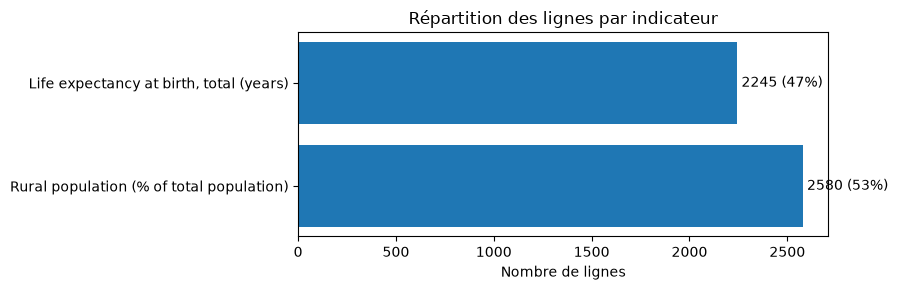

In [48]:
decrire_indicateurs(df_demo, col_indicateur="Indicator", col_valeur="Value", col_pays="Country", col_annee="Time")

La colonne ne contient que deux indicateurs, répartis de façon presque égale : la part de population rurale
(2 580 lignes, 53 %) et l'espérance de vie à la naissance (2 245 lignes, 47 %). Ils ne mesurent pas la même chose,
l'un s'exprime en années avec une médiane de 73, l'autre en pourcentage avec une médiane de 42, et ils ne couvrent pas
tout à fait la même période : de 2010 à 2020 pour l'espérance de vie, de 2010 à 2021 pour la population rurale.

La synthèse fait aussi apparaître une espérance de vie maximale de 820 ans, ce qui est impossible. On y revient
dans l'exploration.

Laisser ces deux indicateurs dans la même colonne fausserait toutes les statistiques. On place donc chacun
dans sa propre colonne, avec une ligne par pays et par année.

In [49]:
df_demo = separer_indicateurs(
    df_demo,
    col_indicateur="Indicator",
    col_valeur="Value",
    colonnes_cles=["LOCATION", "Country", "Time"],
    noms_colonnes={
        "Life expectancy at birth, total (years)": "Esperance_vie",
        "Rural population (% of total population)": "Population_rurale_pct",
    },
)
display(df_demo.head())

,LOCATION,Country,Time,Esperance_vie,Population_rurale_pct
0,ABW,Aruba,2010,75.0,57.0
1,ABW,Aruba,2011,75.0,57.0
2,ABW,Aruba,2012,76.0,57.0
3,ABW,Aruba,2013,76.0,57.0
4,ABW,Aruba,2014,76.0,57.0


### 3.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
Esperance_vie,346,13.4
Population_rurale_pct,131,5.1
LOCATION,0,0.0
Time,0,0.0
Country,0,0.0


Lignes sans aucune valeur : 49 sur 2,591 (1.9%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (216 pays x 12 années) : 2,592
Couples pays + année présents : 2,591
Couples pays + année absents : 1

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Esperance_vie,2245.0,117.00,179.42,46.0,66.0,73.0,78.0,820.0
Population_rurale_pct,2460.0,42.68,23.46,1.0,23.0,42.0,61.0,100.0


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Esperance_vie,Australia,2010,820.0
Population_rurale_pct,Australia,2010,100.0



Pays distincts : 216
Pays sans code ISO : []
Années de première donnée les plus fréquentes (nombre de pays) :


Time
2010    213
2012      1
Name: count, dtype: int64

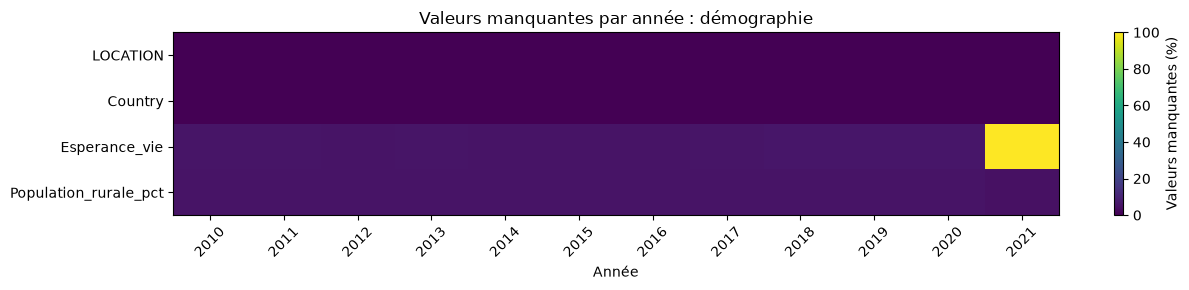

In [50]:
explorer(df_demo, "démographie", col_pays="Country", col_annee="Time", col_iso="LOCATION")

Après la séparation des indicateurs, le fichier compte 2 591 lignes pour 216 pays de 2010 à 2021, sans doublon
et avec un code ISO pour chaque pays. Un seul couple pays et année est absent : Saint-Martin (partie française)
n'a pas de ligne pour 2021.

Les valeurs manquantes s'expliquent pour l'essentiel. L'espérance de vie manque à 13,4 % : l'indicateur s'arrête
en 2020, ce qui vide toute l'année 2021, et dix petits territoires (Andorre, Monaco, Saint-Marin, Nauru, etc.)
n'ont aucune valeur. Ces vides sont laissés tels quels, car il n'y a aucune valeur à reconstituer : les analyses
portant sur l'espérance de vie se limiteront à la période 2010 à 2020 et aux pays renseignés. La population rurale
manque à 5,1 %, presque uniquement pour des villes-États ou des territoires entièrement urbains (Singapour,
Hong Kong, Macao, Monaco, Gibraltar, etc.). Pour ces territoires, le vide correspond à une population rurale nulle
et sera remplacé par 0. Les lignes qui n'ont aucune des deux valeurs seront supprimées.

Les statistiques font ressortir une espérance de vie maximale de 820 ans et une population rurale de 100 %
pour l'Australie, deux valeurs impossibles. On regarde d'abord les valeurs d'espérance de vie supérieures à 100 ans.

In [51]:
# Les valeurs supérieures à 100 ans et, pour les pays concernés, les autres années de leur série
esperance = df_demo["Esperance_vie"]
print("Valeurs supérieures à 100 :", esperance[esperance > 100].unique())

pays_820 = df_demo.loc[esperance == 820, "Country"].unique()
autres_annees = df_demo[df_demo["Country"].isin(pays_820) & (esperance != 820)]["Esperance_vie"]
print(f"{(esperance == 820).sum()} valeurs dans {len(pays_820)} pays, "
      f"autres années entre {autres_annees.min():.0f} et {autres_annees.max():.0f} ans")

Valeurs supérieures à 100 : [820.]
137 valeurs dans 31 pays, autres années entre 79 et 84 ans


Les 137 valeurs concernées valent toutes exactement 820 et touchent 31 pays à forte espérance de vie (Australie,
Canada, Suède, France, etc.). Pour ces pays, les autres années de la série se situent entre 79 et 84 ans, et la France
passe par exemple de 83 à 820 d'une année sur l'autre. Il s'agit d'une erreur de saisie, 82,0 ayant perdu sa virgule :
ces valeurs seront remplacées par 82. Une fois ces valeurs écartées, l'espérance de vie varie entre 46 et 85 ans,
ce qui est cohérent.

La population rurale à 100 % est examinée dans la détection des anomalies, qui classe les valeurs les plus élevées.

### 3.3 Détection des anomalies

In [52]:
for indicateur in ["Esperance_vie", "Population_rurale_pct"]:
    print(f"\n===== {indicateur} =====")
    detecter_anomalies(df_demo, colonnes_valeurs=["Esperance_vie", "Population_rurale_pct"],
                       col_cible=indicateur, col_pays="Country", col_annee="Time", col_iso="LOCATION")


===== Esperance_vie =====
Codes ISO partagés par plusieurs pays : 0
Pays avec plusieurs codes ISO : 0

Lignes où Esperance_vie vaut 0 : 0


,count,min,max
Country,,,


Lignes avec au moins une valeur manquante : 428


,Manquants
Esperance_vie,346
Population_rurale_pct,131


Pays avec des années absentes au milieu de leur série : 0


...

,debut,fin
Country,,
Saint-Martin (French part),2010,2020


Variations annuelles de plus de 100% : 0 dans 0 pays


Series([], Name: count, dtype: int64)

Les 10 pays au pic le plus élevé


,Country,Time,Population_rurale_pct
120,Australia,2010,100.0
2423,United States of America,2010,100.0
156,Burundi,2010,89.0
1847,Papua New Guinea,2010,87.0
1332,Liechtenstein,2010,86.0
1631,Malawi,2010,84.0
1679,Niger,2010,84.0
720,Ethiopia,2010,83.0
1739,Nepal,2010,83.0
1979,Rwanda,2010,83.0


La détection confirme les erreurs repérées à l'exploration et n'en fait pas apparaître d'autre. Les codes ISO
sont cohérents, il n'y a aucune valeur nulle et aucune année absente au milieu d'une série.

Pour l'espérance de vie, les 38 variations de plus de 100 % et les dix valeurs les plus élevées viennent toutes
des valeurs à 820 : chaque passage de 83 à 820, puis de 820 à 83, compte comme une variation. Une fois ces valeurs
écartées, les seules baisses marquées correspondent à des événements réels, comme le Covid en 2020 (Azerbaïdjan,
Équateur), le séisme en Haïti en 2010 ou la guerre en Syrie en 2012. Elles sont conservées. La seule série
incomplète est celle de Saint-Martin (partie française), qui n'a pas de ligne pour 2021.

Pour la population rurale, aucune variation brutale n'apparaît. Le classement des valeurs les plus élevées place
l'Australie et les États-Unis en tête, à 100 % sur toutes les années, loin devant le Burundi (89 %). C'est impossible
pour deux pays aussi urbanisés. Comme on ne connaît pas la vraie valeur, ces données seront remplacées par
des valeurs manquantes plutôt que corrigées au hasard ; les valeurs suivantes du classement sont plausibles.

### 3.4 Correction des anomalies

Les corrections suivent un ordre précis. Les lignes vides sont supprimées avant de mettre à 0 la population rurale
des territoires urbains, sinon les lignes de Monaco ou de Nauru, vides sur les deux indicateurs, prendraient
une valeur rurale nulle et ne seraient plus considérées comme vides. Saint-Martin (partie française) n'est pas
traité comme un territoire urbain, faute de certitude ; sa population rurale reste manquante.

In [53]:
# Territoires entièrement urbains : la population rurale y est absente car nulle
TERRITOIRES_URBAINS = [
    "Bermuda", "Cayman Islands", "China, Hong Kong Special Administrative Region",
    "China, Macao Special Administrative Region", "Gibraltar", "Kuwait", "Monaco",
    "Nauru", "Singapore", "Sint Maarten (Dutch part)",
]


def corriger_demographie(df):
    """Corrige les erreurs du fichier démographique. Renvoie un nouveau DataFrame."""

    df = df.copy()
    print(f"Départ : {len(df):,} lignes")

    # 1. Espérance de vie à 820 : 82,0 a perdu sa virgule
    erreurs_820 = df["Esperance_vie"] == 820
    df.loc[erreurs_820, "Esperance_vie"] = 82
    print(f"Espérance de vie 820 remplacée par 82 : {erreurs_820.sum()}")

    # 2. Population rurale à 100 % pour l'Australie et les États-Unis : vraie valeur inconnue
    rurale_impossible = df["Country"].isin(["Australia", "United States of America"]) & (
        df["Population_rurale_pct"] == 100
    )
    df.loc[rurale_impossible, "Population_rurale_pct"] = None
    print(f"Population rurale à 100 % passée en valeur manquante : {rurale_impossible.sum()}")

    # 3. Lignes sans aucune valeur (avant l'étape 4, qui remplirait la population rurale)
    lignes_vides = df[["Esperance_vie", "Population_rurale_pct"]].isna().all(axis=1)
    df = df[~lignes_vides]
    print(f"Lignes vides supprimées : {lignes_vides.sum()}")

    # 4. Territoires entièrement urbains : population rurale nulle
    rurale_nulle = df["Country"].isin(TERRITOIRES_URBAINS) & df["Population_rurale_pct"].isna()
    df.loc[rurale_nulle, "Population_rurale_pct"] = 0
    print(f"Population rurale mise à 0 (territoires urbains) : {rurale_nulle.sum()}")

    print(f"Arrivée : {len(df):,} lignes pour {df['Country'].nunique()} pays")
    return df.reset_index(drop=True)


df_demo = corriger_demographie(df_demo)

Départ : 2,591 lignes
Espérance de vie 820 remplacée par 82 : 137
Population rurale à 100 % passée en valeur manquante : 24
Lignes vides supprimées : 51
Population rurale mise à 0 (territoires urbains) : 71
Arrivée : 2,540 lignes pour 214 pays


Les 137 valeurs à 820 sont remplacées par 82, et l'espérance de vie varie désormais entre 46 et 85 ans.
On supprime 51 lignes vides et non 49 : une fois la population rurale de l'Australie et des États-Unis passée
en valeur manquante, leur ligne de 2021 devient vide, puisque l'espérance de vie de cette année n'est pas publiée.
Monaco et Nauru n'ont aucune valeur sur aucune année et disparaissent entièrement, ce qui laisse 214 pays.

### 3.5 Tests de qualité et sauvegarde

In [54]:
tester_qualite(df_demo, colonnes_valeurs=["Esperance_vie", "Population_rurale_pct"],
               col_pays="Country", col_annee="Time", col_iso="LOCATION",
               periode=(2010, 2021), manquants_autorises=True)

df_demo.to_csv(DOSSIER_PROPRE / "demographie.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 2010 et 2021,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune ligne entièrement vide,OK


Les 8 règles sont respectées.


Le fichier démographique est prêt : 2 540 lignes pour 214 pays de 2010 à 2021. Les valeurs manquantes qui restent
sont assumées : l'espérance de vie de 2021, qui n'est pas publiée, celle de huit petits territoires qui n'en ont
aucune et de quatre années de Curaçao, ainsi que la population rurale de l'Australie, des États-Unis et de Saint-Martin.

## 4. Population

Ce fichier donne la population de chaque pays de 2000 à 2022, exprimée en milliers d'habitants. Dans l'étude,
elle sert à deux choses : filtrer les pays de plus d'un million d'habitants pour les classements d'émissions
par habitant, et calculer le PIB par habitant.

| Colonne | Signification |
|---|---|
| LOCATION | Code ISO du pays à trois lettres |
| Country | Nom du pays |
| Time | Année de la mesure |
| Value | Population, en milliers d'habitants |

### 4.1 Lecture et contrôle des types

In [55]:
df_population = lire_et_diagnostiquer(FICHIERS["population"])

Population (thousands).csv : 5,171 lignes x 4 colonnes


,LOCATION,Country,Time,Value
0,CZE,Czechia,2000,10289
1,CZE,Czechia,2001,10271
2,CZE,Czechia,2002,10252
3,CZE,Czechia,2003,10239
4,CZE,Czechia,2004,10239


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
LOCATION,str,0.0,,"[CZE, SYC, TKM]"
Country,str,0.0,,"[Czechia, Seychelles, Turkmenistan]"
Time,int64,100.0,,[]
Value,int64,100.0,,[]


Le fichier compte 5 171 lignes et 4 colonnes : le code ISO du pays, son nom, l'année et la population. Les types
sont corrects dès la lecture, Time et Value étant des entiers : aucune conversion n'est nécessaire.

### 4.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
LOCATION,0,0.0
Country,0,0.0
Time,0,0.0
Value,0,0.0


Lignes sans aucune valeur : 0 sur 5,171 (0.0%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (231 pays x 23 années) : 5,313
Couples pays + année présents : 5,171
Couples pays + année absents : 142

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Value,5171.0,30291.91,127580.85,1.0,396.5,5087.0,18637.5,1448471.0


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Value,Chine,2022,1448471



Pays distincts : 231
Pays sans code ISO : []
Années de première donnée les plus fréquentes (nombre de pays) :


Time
2000    225
2017      2
2001      1
2012      1
2016      1
Name: count, dtype: int64

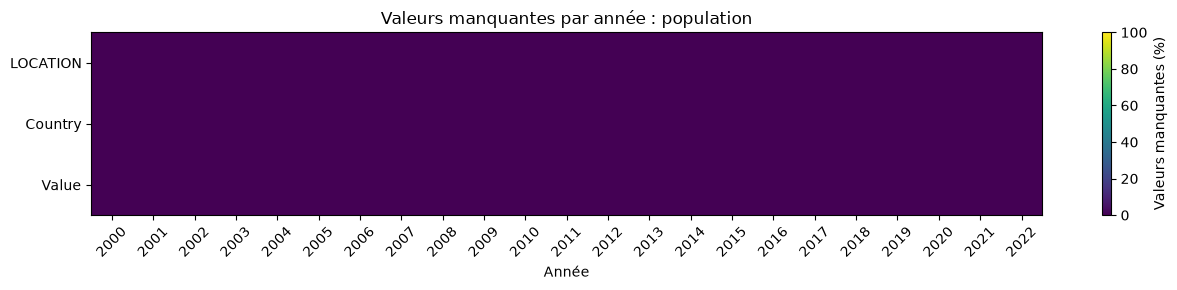

In [56]:
explorer(df_population, "population", col_pays="Country", col_annee="Time", col_iso="LOCATION")

Le fichier couvre 231 pays de 2000 à 2022, chacun avec un code ISO. Il n'y a aucune valeur manquante, aucun doublon
et aucune valeur négative. Les valeurs vont de 1 millier d'habitants pour Tokelau à 1,45 milliard pour la Chine
en 2022, ce qui correspond aux chiffres publiés. La distribution est très asymétrique : la moyenne (30,3 millions)
est six fois plus élevée que la médiane (5,1 millions), car quelques pays très peuplés tirent la moyenne vers le haut.

L'absence de valeurs manquantes ne garantit pourtant pas que les données sont complètes, et la heatmap ne montre
rien pour la même raison. Si chaque pays était présent toutes les années, le fichier devrait compter
231 × 23 = 5 313 lignes : il en manque donc 142. Ces années absentes n'apparaissent pas comme des valeurs
manquantes, car les lignes correspondantes n'existent pas. On regarde quels pays sont concernés.

Les noms de pays mélangent par ailleurs le français et l'anglais (« Chine », « Inde » à côté de « Germany »),
ce qui confirme que la jointure avec les autres fichiers devra se faire sur le code ISO.

In [57]:
# Pour chaque pays : nombre d'années présentes, première et dernière année
nb_annees_attendues = df_population["Time"].nunique()
couverture = df_population.groupby("Country")["Time"].agg(nb_annees="count", debut="min", fin="max")

pays_incomplets = couverture[couverture["nb_annees"] < nb_annees_attendues].sort_values("nb_annees")
print(f"Pays incomplets : {len(pays_incomplets)}")
display(pays_incomplets)

Pays incomplets : 18


,nb_annees,debut,fin
Country,,,
San Marino,4,2017,2020
Singapore,4,2017,2020
Monaco,6,2016,2021
Bosnia and Herzegovina,7,2000,2022
Republic of Moldova,8,2013,2020
Japan,8,2012,2019
Ukraine,14,2000,2013
Puerto Rico,15,2000,2022
Brazil,18,2001,2020


Les 142 années absentes se répartissent entre 18 pays. Ces trous prennent trois formes, qui peuvent se cumuler :
un début de série après 2000 (6 pays), une fin de série avant 2022 (16 pays) et des années manquantes au milieu
de la série (3 pays). Quand la première année vaut 2000 et la dernière 2022 mais que le nombre d'années est inférieur
à 23, comme pour la Bosnie ou Porto Rico, c'est qu'il manque des années au milieu.

### 4.3 Détection des anomalies

Une population évolue lentement : le seuil de variation est abaissé à 10 %.

In [58]:
detecter_anomalies(df_population, colonnes_valeurs=["Value"], col_cible="Value",
                   col_pays="Country", col_annee="Time", col_iso="LOCATION", seuil_variation=0.1)

Codes ISO partagés par plusieurs pays : 0
Pays avec plusieurs codes ISO : 0

Lignes où Value vaut 0 : 0


,count,min,max
Country,,,


Lignes avec au moins une valeur manquante : 0


,Manquants
Value,0


Pays avec des années absentes au milieu de leur série : 3


...

,debut,fin
Country,,
Singapore,2017,2020
San Marino,2017,2020
Monaco,2016,2021
Republic of Moldova,2013,2020
Japan,2012,2019
Brazil,2001,2020
Cyprus,2000,2020
Azerbaijan,2000,2020
Liechtenstein,2000,2020


Variations annuelles de plus de 10% : 26 dans 11 pays


Country
Qatar                          7
United Arab Emirates           5
Saint-Barthélemy               3
Montserrat                     2
Saint Helena                   2
Tuvalu                         2
Bosnia and Herzegovina         1
Falkland Islands (Malvinas)    1
Nauru                          1
Puerto Rico                    1
Name: count, dtype: int64

Les 10 pays au pic le plus élevé


,Country,Time,Value
4938,Chine,2022,1448471
3263,Inde,2022,1406632
4524,United States of America,2019,329065
3982,Indonesia,2022,279135
992,Pakistan,2022,229489
923,Nigeria,2022,216747
4092,Brazil,2020,212559
741,Bangladesh,2022,167886
3617,Russian Federation,2000,146405
3662,Mexico,2022,131563


La sortie donne le nombre de variations par pays, mais pas leur année ni leur ampleur. On les affiche en détail.

In [59]:
# Détail des variations de plus de 10 % : pays, année, population et variation
population_triee = df_population.sort_values(["Country", "Time"])
variation = population_triee.groupby("Country")["Value"].pct_change()

details_variations = population_triee.assign(variation_pct=(variation * 100).round(1))
display(details_variations.loc[variation.abs() > 0.1, ["Country", "Time", "Value", "variation_pct"]])

,Country,Time,Value,variation_pct
2348,Bosnia and Herzegovina,2018,3324,-11.5
5008,Falkland Islands (Malvinas),2021,4,33.3
560,Montserrat,2002,4,-20.0
561,Montserrat,2003,5,25.0
3931,Nauru,2017,11,10.0
2468,Puerto Rico,2021,2828,-20.0
2833,Qatar,2004,753,10.4
2834,Qatar,2005,865,14.9
2835,Qatar,2006,1023,18.3
2836,Qatar,2007,1218,19.1


Les codes ISO sont cohérents, et il n'y a ni valeur nulle ni valeur manquante.

La détection confirme les 18 pays incomplets. Trois ont des années absentes au milieu de leur série : la Bosnie
(de 2002 à 2017), Porto Rico (de 2013 à 2020) et le Brésil (2006 et 2010). Seize pays, dont le Brésil, commencent
après 2000 ou s'arrêtent avant 2022, comme le Japon (de 2012 à 2019) ou les États-Unis (jusqu'en 2019).

Avec un seuil de 10 %, on relève 26 variations dans 11 pays, de trois natures différentes. Celles du Qatar
(de 2004 à 2010) et des Émirats arabes unis (de 2005 à 2009), entre 10 et 19 % par an, sont réelles et correspondent
à l'afflux de travailleurs étrangers pendant le boom gazier et immobilier. Celles de la Bosnie et de Porto Rico
sont mesurées sur toute la durée de leur trou, et non sur une seule année. Les autres concernent
des micro-territoires comme Tuvalu, Montserrat ou Saint-Barthélemy, dont la population est arrondie au millier :
passer de 9 à 10 milliers d'habitants suffit à faire une variation de 11 %. Ce sont des effets d'arrondi,
sans signification.

Aucune valeur n'est donc erronée. Les populations les plus élevées sont celles de la Chine, de l'Inde et des États-Unis,
ce qui est cohérent.

### 4.4 Correction des anomalies

| Pays | Années manquantes | Traitement |
|---|---|---|
| Brésil | 2006, 2010 | Interpolées : années isolées encadrées par deux valeurs connues |
| Brésil | 2000, 2021 | Non reconstituées : en bord de série |
| Bosnie | de 2002 à 2017 | Non reconstituées : trou trop long |
| Porto Rico | de 2013 à 2020 | Non reconstituées : trou trop long |
| Saint-Marin, Singapour | de 2000 à 2016, 2021 | Non reconstituées : en dehors de la série |
| Monaco | de 2000 à 2015 | Non reconstituées : avant le début de la série |
| Moldavie | de 2000 à 2012, 2021 | Non reconstituées : en dehors de la série |
| Japon | de 2000 à 2011, 2020, 2021 | Non reconstituées : en dehors de la série |
| Ukraine | de 2014 à 2021 | Non reconstituées : après la fin de la série |
| États-Unis | 2020, 2021 | Non reconstituées : après la fin de la série |
| France, Irlande, Lettonie, Lituanie, Azerbaïdjan, Chypre, Serbie, Liechtenstein | 2021 | Non reconstituées : après la fin de la série |

Une année manquante n'est interpolée que si elle est isolée et encadrée par deux valeurs connues. C'est le seul cas
où l'estimation est fiable, car la population évolue de façon très régulière d'une année sur l'autre. Seul le Brésil
est dans ce cas, pour 2006 et 2010. Toutes les autres années manquantes sont laissées absentes : elles se trouvent
soit dans un trou trop long, soit avant le début ou après la fin de la série, et les reconstituer reviendrait
à inventer des données.

Ces années absentes ont une conséquence sur le PIB par habitant, qui ne peut pas être calculé sans population.
Par exemple, le Japon n'a pas de population en 2010 : sa croissance du PIB par habitant entre 2010 et 2019
ne pourra pas être mesurée, mais il restera présent dans le classement de la croissance du PIB. Elles n'affectent pas
en revanche le filtre des pays de plus d'un million d'habitants, qui utilisera la dernière population connue
de chaque pays. Enfin, l'année 2022 est retirée pour tous les pays, car les émissions s'arrêtent en 2021.

In [60]:
def corriger_population(df):
    """Interpole les années isolées et retire 2022. Renvoie un nouveau DataFrame."""

    print(f"Départ : {len(df):,} lignes")

    # Années isolées encadrées par deux valeurs connues (Brésil 2006 et 2010)
    df = completer_annees(df, colonnes_valeurs=["Value"],
                          col_pays="Country", col_annee="Time", col_iso="LOCATION")
    df["Value"] = df["Value"].round().astype(int)   # population en milliers entiers, comme le reste du fichier

    # Les émissions s'arrêtent en 2021 : l'année 2022 ne sert à aucune analyse
    nb_2022 = (df["Time"] == 2022).sum()
    df = df[df["Time"] <= 2021].reset_index(drop=True)
    print(f"Lignes de 2022 retirées : {nb_2022}")

    print(f"Arrivée : {len(df):,} lignes pour {df['Country'].nunique()} pays")
    return df


df_population = corriger_population(df_population)

Départ : 5,171 lignes
Lignes interpolées : 2
Lignes de 2022 retirées : 215
Arrivée : 4,958 lignes pour 231 pays


Le Brésil passe ainsi à 188 128 milliers d'habitants en 2006 et 195 701 en 2010, des valeurs situées entre
celles des années voisines.

### 4.5 Tests de qualité et sauvegarde

In [61]:
tester_qualite(df_population, colonnes_valeurs=["Value"], col_pays="Country",
               col_annee="Time", col_iso="LOCATION", periode=(2000, 2021))

df_population.to_csv(DOSSIER_PROPRE / "population.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 2000 et 2021,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune valeur manquante,OK


Les 8 règles sont respectées.


Le fichier de la population est prêt : 4 958 lignes pour 231 pays de 2000 à 2021. Les années absentes
non reconstituées sont assumées et apparaîtront comme des valeurs manquantes au moment de construire
la table de faits.

## 5. Dépenses publiques d'éducation

Ce fichier mesure la part du PIB que l'État consacre à l'enseignement primaire, de 2010 à 2022. Il ne donne pas
le niveau d'éducation d'un pays, mais l'effort financier public pour l'école primaire : c'est l'hypothèse retenue
pour répondre à la question sur le lien entre émissions et éducation.

| Colonne | Signification |
|---|---|
| Indicator | Nom de l'indicateur |
| LOCATION | Code ISO du pays à trois lettres |
| Country | Nom du pays |
| Time | Année de la mesure |
| Value | Dépenses publiques pour l'enseignement primaire, en % du PIB |

### 5.1 Lecture et contrôle des types

In [62]:
df_education = lire_et_diagnostiquer(FICHIERS["education"])

Governement_Expenditure_education_%_of_GDP.csv : 1,236 lignes x 5 colonnes


,Indicator,LOCATION,Country,Time,Value
0,Government expenditure on primary education as...,PER,Peru,2010,1.14292
1,Government expenditure on primary education as...,PER,Peru,2011,1.03425
2,Government expenditure on primary education as...,PER,Peru,2012,1.07009
3,Government expenditure on primary education as...,PER,Peru,2013,1.30871
4,Government expenditure on primary education as...,PER,Peru,2014,1.42186


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
Indicator,str,0.0,,[Government expenditure on primary education a...
LOCATION,str,0.0,,"[PER, MNG, SGP]"
Country,str,0.0,,"[Peru, Mongolia, Singapore]"
Time,int64,100.0,,[]
Value,float64,100.0,,[]


Le fichier compte 1 236 lignes et 5 colonnes, et les types sont corrects dès la lecture : aucune conversion
n'est nécessaire. La colonne Indicator ne montre qu'un seul libellé dans les exemples. On vérifie qu'elle
ne contient bien qu'un indicateur avant de la retirer.

In [63]:
print("Nombre d'indicateurs différents :", df_education["Indicator"].nunique())

Nombre d'indicateurs différents : 1


La colonne ne contient qu'un indicateur, les dépenses publiques consacrées à l'enseignement primaire en pourcentage
du PIB. Elle n'apporte donc aucune information et elle est retirée, et Value est renommée pour indiquer
ce qu'elle mesure.

In [64]:
df_education = (
    df_education.drop(columns="Indicator")
    .rename(columns={"Value": "Depenses_education_primaire_pct_pib"})
)

### 5.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
Depenses_education_primaire_pct_pib,13,1.1
LOCATION,0,0.0
Country,0,0.0
Time,0,0.0


Lignes sans aucune valeur : 13 sur 1,236 (1.1%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (173 pays x 13 années) : 2,249
Couples pays + année présents : 1,236
Couples pays + année absents : 1,013

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Depenses_education_primaire_pct_pib,1223.0,1.49,0.76,0.02,0.97,1.41,1.81,5.64


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Depenses_education_primaire_pct_pib,Greenland,2013,5.64



Pays distincts : 173
Pays sans code ISO : []
Années de première donnée les plus fréquentes (nombre de pays) :


Time
2010    108
2011     18
2012     14
2015     10
2013      5
Name: count, dtype: int64

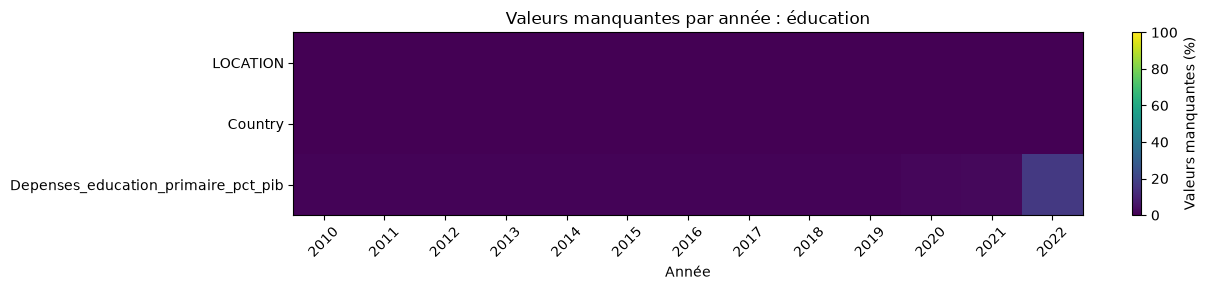

In [65]:
explorer(df_education, "éducation", col_pays="Country", col_annee="Time", col_iso="LOCATION")

Le fichier couvre 173 pays de 2010 à 2022, sans doublon ni valeur négative, chacun avec un code ISO.
Les 13 valeurs manquantes et les 13 lignes sans aucune valeur sont les mêmes lignes : le fichier n'ayant qu'une colonne
de valeurs, une valeur manquante rend la ligne entièrement vide. On verra à la détection des anomalies à quels pays
elles appartiennent.

L'exploration montre surtout que la couverture est incomplète : 2 249 couples pays et année sont attendus, mais
1 236 seulement sont présents, soit 1 013 années absentes, et seuls 108 pays commencent en 2010. Ces années absentes
n'apparaissent pas comme des valeurs manquantes, car les lignes correspondantes n'existent pas. Pour savoir
où elles se trouvent, on compte le nombre de pays renseignés chaque année, puis le nombre d'années renseignées
pour chaque pays.

Les dépenses vont de 0,02 % à 5,6 % du PIB, avec une médiane de 1,4 %. Le maximum revient au Groenland en 2013.

In [66]:
colonne = "Depenses_education_primaire_pct_pib"
education_renseignee = df_education.dropna(subset=[colonne])

# Nombre de pays renseignés chaque année
display(education_renseignee.groupby("Time")["Country"].nunique().to_frame("Nombre de pays"))

# Nombre d'années renseignées par pays
annees_par_pays = education_renseignee.groupby("Country")["Time"].nunique()
repartition = pd.cut(annees_par_pays, bins=[0, 3, 6, 9, 12, 13],
                     labels=["1 à 3", "4 à 6", "7 à 9", "10 à 12", "13"])
display(repartition.value_counts().sort_index().to_frame("Nombre de pays"))

,Nombre de pays
Time,
2010,108
2011,110
2012,113
2013,120
2014,113
2015,114
2016,111
2017,106
2018,106


,Nombre de pays
Time,
1 à 3,40
4 à 6,34
7 à 9,33
10 à 12,63
13,2


Le nombre de pays renseignés reste stable, entre 106 et 120 par an, de 2010 à 2019, puis s'effondre à 61 en 2020,
49 en 2021 et 5 en 2022. Les années récentes ne sont donc pas représentatives, probablement en raison du délai
de publication de ce type de données. Même sur la période stable, chaque année ne couvre qu'environ deux tiers
des pays, qui ne sont renseignés que par intermittence : seuls 2 pays le sont les 13 années, 40 le sont
trois années ou moins.

Ces absences ne sont pas reconstituées, car cela reviendrait à inventer près de la moitié du fichier.
Pour la question sur le lien entre émissions et éducation, on ne travaillera pas sur une année isolée,
mais sur la médiane de chaque pays de 2010 à 2019, calculée sur les années disponibles.

### 5.3 Détection des anomalies

In [67]:
detecter_anomalies(df_education, colonnes_valeurs=[colonne], col_cible=colonne,
                   col_pays="Country", col_annee="Time", col_iso="LOCATION")

Codes ISO partagés par plusieurs pays : 0
Pays avec plusieurs codes ISO : 0

Lignes où Depenses_education_primaire_pct_pib vaut 0 : 0


,count,min,max
Country,,,


Lignes avec au moins une valeur manquante : 13


,Manquants
Depenses_education_primaire_pct_pib,13


Pays avec des années absentes au milieu de leur série : 60


...

,debut,fin
Country,,
Haiti,2021,2021
Azerbaijan,2019,2020
Marshall Islands,2019,2019
United Arab Emirates,2019,2021
Lesotho,2018,2018
...,...,...
Switzerland,2010,2018
United Kingdom of Great Britain and Northern Ireland,2010,2019
Uganda,2010,2014


Variations annuelles de plus de 100% : 7 dans 7 pays


Country
Democratic Republic of the Congo    1
Ghana                               1
Liberia                             1
Rwanda                              1
Sierra Leone                        1
Timor-Leste                         1
Zimbabwe                            1
Name: count, dtype: int64

Les 10 pays au pic le plus élevé


,Country,Time,Depenses_education_primaire_pct_pib
1216,Greenland,2013,5.63519
1178,Marshall Islands,2019,5.11216
456,Kiribati,2020,4.45957
1015,Sierra Leone,2021,4.41674
494,Lesotho,2018,4.07575
1232,Faeroe Islands,2020,4.02798
329,Timor-Leste,2012,3.98709
1204,Bolivia (Plurinational State of),2010,3.76352
918,Cuba,2010,3.72731
1142,Ghana,2011,3.70317


Les codes ISO sont cohérents et il n'y a aucune valeur nulle. Les années absentes, au milieu des séries comme
au début ou à la fin, confirment la couverture intermittente vue à l'exploration.

Deux points demandent à être vérifiés : les 13 lignes vides, et les valeurs les plus faibles, autour de 0,02 %
du PIB pour le Kazakhstan, près de cinquante fois moins que la médiane. On regarde aussi les sept variations
de plus de 100 %, dont celle du Timor oriental en 2019, la plus forte.

In [68]:
lignes_vides = df_education[df_education[colonne].isna()]
print("Lignes vides :", len(lignes_vides), "| pays :", lignes_vides["Country"].unique().tolist())

for pays in ["Kazakhstan", "Timor-Leste"]:
    serie = df_education[df_education["Country"] == pays].set_index("Time")[colonne]
    print(pays, serie.round(2).to_dict())

Lignes vides : 13 | pays : ['Holy See']
Kazakhstan {2017: 0.02, 2018: 0.02, 2019: 0.02}
Timor-Leste {2012: 3.99, 2013: 3.2, 2014: 3.67, 2015: 3.01, 2016: 3.13, 2017: 0.34, 2018: 0.18, 2019: 2.5, 2020: 2.62, 2021: 3.54}


Les 13 lignes vides appartiennent toutes au Saint-Siège, pour lequel aucune dépense n'a été publiée sur l'ensemble
de la période.

Le Kazakhstan n'est renseigné que de 2017 à 2019, autour de 0,02 % du PIB, ce qui est peu crédible pour un pays
qui scolarise toute sa population. Le Timor oriental passe de 3,13 % en 2016 à 0,34 % puis 0,18 %, avant de remonter
à 2,50 % en 2019 : la variation signalée en 2019 vient de cette chute isolée au milieu d'une série stable,
qui ressemble à une erreur de saisie. Comme on ne connaît pas les vraies valeurs, ces lignes seront retirées
plutôt que corrigées.

Les autres variations de plus de 100 % concernent des pays aux séries courtes et irrégulières (Liberia, Zimbabwe,
Ghana, etc.), et rien ne permet d'en faire des erreurs : elles sont conservées. La médiane utilisée à l'analyse
limitera de toute façon leur effet.

### 5.4 Correction des anomalies

In [69]:
def corriger_education(df):
    """Retire les lignes vides et les valeurs invraisemblables. Renvoie un nouveau DataFrame."""

    colonne = "Depenses_education_primaire_pct_pib"
    print(f"Départ : {len(df):,} lignes pour {df['Country'].nunique()} pays")

    # 1. Lignes vides : le Saint-Siège n'a aucune valeur sur toute la période
    nb_vides = df[colonne].isna().sum()
    df = df.dropna(subset=[colonne])
    print(f"Lignes vides supprimées (Saint-Siège) : {nb_vides}")

    # 2. Valeurs invraisemblables, dont la vraie valeur est inconnue : on les retire plutôt que de les corriger
    #    Kazakhstan 2017 à 2019 : environ 0,02 % du PIB, près de 50 fois moins que la médiane des pays
    #    Timor oriental 2017 et 2018 : chute à 0,34 et 0,18 % entre 3,13 % (2016) et 2,50 % (2019)
    invraisemblables = (
        ((df["Country"] == "Kazakhstan") & df["Time"].between(2017, 2019))
        | ((df["Country"] == "Timor-Leste") & df["Time"].between(2017, 2018))
    )
    df = df[~invraisemblables]
    print(f"Valeurs invraisemblables supprimées : {invraisemblables.sum()}")

    # Les années absentes ne sont pas reconstituées : l'analyse utilisera la médiane de chaque pays

    print(f"Arrivée : {len(df):,} lignes pour {df['Country'].nunique()} pays")
    return df.reset_index(drop=True)


df_education = corriger_education(df_education)

Départ : 1,236 lignes pour 173 pays
Lignes vides supprimées (Saint-Siège) : 13
Valeurs invraisemblables supprimées : 5
Arrivée : 1,218 lignes pour 171 pays


Le Saint-Siège et le Kazakhstan disparaissent, puisque toutes leurs valeurs étaient vides ou invraisemblables,
et le fichier passe de 173 à 171 pays. La plus petite valeur est désormais de 0,11 %, pour Sao Tomé-et-Principe.

### 5.5 Tests de qualité et sauvegarde

In [70]:
tester_qualite(df_education, colonnes_valeurs=[colonne], col_pays="Country",
               col_annee="Time", col_iso="LOCATION", periode=(2010, 2022))

df_education.to_csv(DOSSIER_PROPRE / "education.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 2010 et 2022,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune valeur manquante,OK


Les 8 règles sont respectées.


Le fichier de l'éducation est prêt : 1 218 lignes pour 171 pays de 2010 à 2022. Sa couverture intermittente
est assumée et sera traitée à l'analyse par la médiane de chaque pays de 2010 à 2019.

## 6. Dépenses de préservation du patrimoine

Ce fichier mesure l'effort financier qu'un pays consacre à la préservation, la protection et la conservation
de son patrimoine culturel (monuments, sites historiques, musées, archives) et naturel (parcs, réserves,
sites protégés). La dépense est exprimée par habitant et inclut les dépenses publiques et privées.

L'unité est le dollar en parité de pouvoir d'achat constante de 2017. La parité de pouvoir d'achat corrige
les différences de prix entre pays, et les prix constants de 2017 retirent l'effet de l'inflation :
les montants sont comparables entre pays comme d'une année à l'autre. Cet indicateur ne répond directement à aucune
des trois questions de l'étude ; il complète le portrait des zones d'implantation envisagées.

| Colonne | Signification |
|---|---|
| Indicator | Nom de l'indicateur |
| LOCATION | Code ISO du pays à trois lettres |
| Country | Nom du pays |
| TIME, Time | Année de la mesure |
| Value | Dépense par habitant, en dollars PPA constants de 2017 |

### 6.1 Lecture et contrôle des types

In [71]:
df_patrimoine = lire_et_diagnostiquer(FICHIERS["patrimoine"])

Expenditure_preservation&conservation.csv : 528 lignes x 6 colonnes


,Indicator,LOCATION,Country,TIME,Time,Value
0,Total per capita expenditure on the preservati...,CZE,Czechia,2018,2018,175.7
1,Total per capita expenditure on the preservati...,CZE,Czechia,2019,2019,170.0
2,Total per capita expenditure on the preservati...,CZE,Czechia,2020,2020,160.6
3,Total per capita expenditure on the preservati...,MEX,Mexico,2018,2018,16.9
4,Total per capita expenditure on the preservati...,MEX,Mexico,2019,2019,13.6


,Type lu,% numérique,Virgule décimale,Exemples non numériques
Colonne,,,,
Indicator,str,0.0,,[Total per capita expenditure on the preservat...
LOCATION,str,0.0,,"[CZE, MEX, PRT]"
Country,str,0.0,,"[Czechia, Mexico, Portugal]"
TIME,int64,100.0,,[]
Time,int64,100.0,,[]
Value,float64,100.0,,[]


Le fichier compte 528 lignes et 6 colonnes, et les types sont corrects dès la lecture : aucune conversion
n'est nécessaire. Deux colonnes posent question : TIME et Time semblent contenir les mêmes années,
et Indicator ne montre qu'un seul libellé dans les exemples. On le vérifie.

In [72]:
print("TIME et Time identiques :", (df_patrimoine["TIME"] == df_patrimoine["Time"]).all())
print("Nombre d'indicateurs différents :", df_patrimoine["Indicator"].nunique())

TIME et Time identiques : True
Nombre d'indicateurs différents : 1


TIME et Time sont identiques sur toutes les lignes, et Indicator ne contient qu'un libellé. Ce format est celui
des exports de bases statistiques internationales, où chaque dimension est fournie à la fois sous forme de code
et de libellé ; pour l'année, les deux sont identiques. TIME et Indicator sont retirées, et Value est renommée
pour indiquer ce qu'elle mesure.

In [73]:
df_patrimoine = (
    df_patrimoine.drop(columns=["TIME", "Indicator"])
    .rename(columns={"Value": "Depenses_patrimoine_par_hab"})
)

### 6.2 Exploration

Valeurs manquantes par colonne


,Manquants,% manquants
Depenses_patrimoine_par_hab,12,2.3
LOCATION,0,0.0
Country,0,0.0
Time,0,0.0


Lignes sans aucune valeur : 12 sur 528 (2.3%)
Lignes dupliquées : 43
Doublons pays + année : 407

Couples pays + année attendus (57 pays x 6 années) : 342
Couples pays + année présents : 121
Couples pays + année absents : 221

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
Depenses_patrimoine_par_hab,516.0,49.61,65.71,0.1,7.7,23.5,68.55,516.6


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
Depenses_patrimoine_par_hab,Malta,2020,516.6



Pays distincts : 57
Pays sans code ISO : []
Années de première donnée les plus fréquentes (nombre de pays) :


Time
2019    18
2020    13
2018    13
2021     6
2017     3
Name: count, dtype: int64

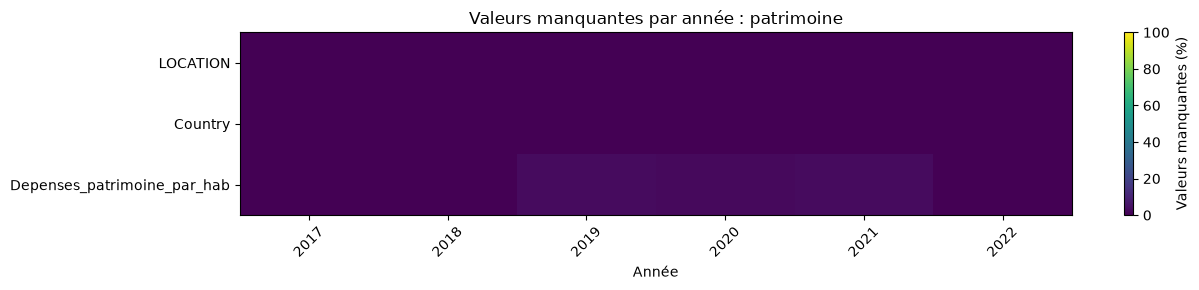

In [74]:
explorer(df_patrimoine, "patrimoine", col_pays="Country", col_annee="Time", col_iso="LOCATION")

La sortie appelle plusieurs remarques.

La colonne des dépenses compte 516 valeurs alors que le fichier a 528 lignes : l'écart correspond exactement
aux 12 valeurs manquantes. On regarde dans la suite à quels pays et à quelles années elles appartiennent, pour savoir
si d'autres valeurs existent pour ces mêmes pays et ces mêmes années, ou si l'information est entièrement absente.

Les deux contrôles de doublons ne mesurent pas la même chose. Le premier compte les lignes identiques sur toutes
les colonnes, c'est-à-dire même pays, même année et même valeur : il y en a 43. Le second compte les lignes qui
partagent seulement le même pays et la même année, quelle que soit la valeur : il y en a 407. Les 43 lignes
identiques font donc partie des 407. Le fichier ne contient en réalité que 121 couples pays et année pour 528 lignes,
soit plus de quatre lignes en moyenne pour un même pays et une même année. Un pays ne pouvant avoir qu'une seule
dépense totale par an, ces lignes multiples ne sont pas normales. Deux explications sont possibles : de vraies erreurs
de saisie, ou plusieurs mesures différentes dont la colonne de description aurait disparu. On affiche ces lignes
dans la suite pour trancher.

Il n'y a aucune valeur négative, et la valeur maximale, 516,6 dollars par habitant pour Malte en 2020,
est plausible pour un petit pays au patrimoine historique important. Les statistiques sont toutefois à lire
avec prudence tant que les lignes multiples ne sont pas traitées.

Enfin, la couverture est faible : 57 pays seulement, et la plupart ne commencent qu'en 2018 ou 2019.

### 6.3 Détection des anomalies

La fonction commune de détection n'est pas adaptée à ce fichier tant que les lignes multiples ne sont pas comprises :
elle calculerait des variations entre des valeurs qui ne mesurent pas la même chose. On analyse donc directement
les deux anomalies révélées par l'exploration : les valeurs manquantes, puis les lignes répétées.

On commence par la forme des valeurs manquantes : pour chaque pays et chaque année concernés, le nombre de lignes
vides, le nombre de lignes renseignées et les valeurs présentes.

In [75]:
colonne = "Depenses_patrimoine_par_hab"

# Couples pays et année qui ont au moins une valeur manquante
couples_avec_vide = df_patrimoine.loc[df_patrimoine[colonne].isna(), ["Country", "Time"]].drop_duplicates()

# Pour chacun : nombre de lignes, de valeurs vides, de valeurs renseignées, et les valeurs présentes
forme_manquants = (
    df_patrimoine.merge(couples_avec_vide, on=["Country", "Time"])
    .groupby(["Country", "Time"])[colonne]
    .agg(lignes="size",
         valeurs_renseignees="count",
         valeurs_presentes=lambda valeurs: sorted(valeurs.dropna(), reverse=True))
)
forme_manquants["valeurs_vides"] = forme_manquants["lignes"] - forme_manquants["valeurs_renseignees"]
display(forme_manquants[["lignes", "valeurs_vides", "valeurs_renseignees", "valeurs_presentes"]])

,,lignes,valeurs_vides,valeurs_renseignees,valeurs_presentes
Country,Time,,,,
Andorra,2021,4,1,3,"[284.2, 175.6, 108.6]"
Burkina Faso,2019,3,3,0,[]
Kazakhstan,2019,3,1,2,"[0.7, 0.6]"
Kenya,2021,2,2,0,[]
Myanmar,2020,2,2,0,[]
Sri Lanka,2020,7,1,6,"[10.0, 9.9, 9.9, 5.7, 4.3, 0.1]"
Uzbekistan,2020,2,2,0,[]


Les 12 valeurs manquantes prennent deux formes. Pour le Burkina Faso, le Kenya, le Myanmar et l'Ouzbékistan,
toutes les lignes sont vides et c'est leur seule année dans le fichier : ces pays n'ont aucune dépense connue
et seront retirés, ce qui ramènera le fichier à 53 pays. Pour Andorre, le Kazakhstan et le Sri Lanka, une seule ligne
est vide alors que d'autres valeurs existent la même année : ces lignes vides pourront être supprimées sans perte.

Ces cas donnent aussi une première piste sur les lignes répétées : pour Andorre, la valeur la plus élevée est la somme
des deux autres (284,2 = 175,6 + 108,6), et de même pour le Sri Lanka. Deux exemples ne suffisent pas à conclure.
On affiche donc toutes les lignes répétées, classées par pays et par année, de la plus grande valeur à la plus petite.

In [76]:
# Lignes qui partagent le même pays et la même année qu'au moins une autre ligne
lignes_en_double = df_patrimoine[df_patrimoine.duplicated(["Country", "Time"], keep=False)].sort_values(
    ["Country", "Time", colonne], ascending=[True, True, False]
)
print(f"Lignes concernées : {len(lignes_en_double)}")
display(lignes_en_double)

Lignes concernées : 520


,LOCATION,Country,Time,Depenses_patrimoine_par_hab
471,ALB,Albania,2021,23.5
497,ALB,Albania,2021,13.9
519,ALB,Albania,2021,9.6
472,AND,Andorra,2021,284.2
520,AND,Andorra,2021,175.6
...,...,...,...,...
518,GBR,United Kingdom of Great Britain and Northern I...,2020,50.7
271,UZB,Uzbekistan,2020,NaN
281,UZB,Uzbekistan,2020,NaN
458,VUT,Vanuatu,2019,1.9


Pour un même pays et une même année, la première valeur semble être la somme des suivantes : pour l'Albanie en 2021,
23,5 est la somme de 13,9 et 9,6. L'hypothèse est la suivante : la valeur la plus élevée est le total,
et les autres en sont des ventilations, par exemple entre dépenses publiques et privées. On la vérifie sur l'ensemble
du fichier. Les ventilations peuvent redonner le total par deux (175,6 + 108,6 = 284,2 pour Andorre) ou toutes
ensemble (5,0 + 1,4 + 0,9 = 7,2 pour le Brésil en 2019, à l'arrondi près) : on teste les deux cas.

In [77]:
tolerance = 0.15   # les valeurs n'ont qu'une décimale : on accepte un petit écart d'arrondi
repetees = lignes_en_double.dropna(subset=[colonne]).copy()

# Pour chaque ligne, la valeur la plus élevée de son couple pays et année (le total supposé)
repetees["total_suppose"] = repetees.groupby(["Country", "Time"])[colonne].transform("max")

# Les autres lignes, plus petites que le total supposé : les ventilations supposées
parties = repetees[repetees[colonne] < repetees["total_suppose"]].reset_index()

# Test 1 : deux ventilations s'additionnent-elles pour donner le total ?
paires = parties.merge(parties, on=["Country", "Time", "total_suppose"], suffixes=("_1", "_2"))
paires = paires[paires["index_1"] < paires["index_2"]]
paires["somme_ok"] = (paires[f"{colonne}_1"] + paires[f"{colonne}_2"] - paires["total_suppose"]).abs() <= tolerance
test_paires = paires.groupby(["Country", "Time"])["somme_ok"].any()

# Test 2 : toutes les ventilations réunies donnent-elles le total ? (à partir de deux ventilations)
somme_parties = parties.groupby(["Country", "Time"]).agg(
    somme=(colonne, "sum"), total=("total_suppose", "first"), nb_parties=(colonne, "size")
)
somme_parties = somme_parties[somme_parties["nb_parties"] >= 2]
test_somme_totale = (somme_parties["somme"] - somme_parties["total"]).abs() <= tolerance

# Un couple confirme l'hypothèse si l'un des deux tests est vrai
confirme = test_paires.reindex(somme_parties.index, fill_value=False) | test_somme_totale
print(f"Couples avec au moins deux ventilations à additionner : {len(confirme)}")
print(f"Couples où le maximum est la somme d'autres valeurs : {confirme.sum()}")

# Couples qui ne confirment pas l'hypothèse : total supposé, ventilations, leur somme et l'écart
exceptions = somme_parties.loc[~confirme].copy()
exceptions["ventilations"] = parties.groupby(["Country", "Time"])[colonne].apply(list)
exceptions["ecart"] = (exceptions["somme"] - exceptions["total"]).round(1)
exceptions["ecart_pct"] = (exceptions["ecart"] / exceptions["total"] * 100).round(1)
display(exceptions[["total", "ventilations", "somme", "ecart", "ecart_pct"]])

# Couples à deux valeurs, qu'on ne peut pas tester par une somme
deux_valeurs = repetees.groupby(["Country", "Time"])[colonne].agg(["size", "nunique"])
deux_valeurs = deux_valeurs[deux_valeurs["size"] == 2]
print(f"Couples à deux valeurs : {len(deux_valeurs)}, dont identiques : {(deux_valeurs['nunique'] == 1).sum()}")

Couples avec au moins deux ventilations à additionner : 87
Couples où le maximum est la somme d'autres valeurs : 85


total  ventilations  \
Country                                            Time                        
United Kingdom of Great Britain and Northern Ir... 2019  113.5  [61.6, 55.2]   
                                                   2020  116.6  [68.5, 50.7]   

                                                         somme  ecart  \
Country                                            Time                 
United Kingdom of Great Britain and Northern Ir... 2019  116.8    3.3   
                                                   2020  119.2    2.6   

                                                         ecart_pct  
Country                                            Time             
United Kingdom of Great Britain and Northern Ir... 2019        2.9  
                                                   2020        2.2

Couples à deux valeurs : 22, dont identiques : 21


L'hypothèse est confirmée pour 85 des 87 couples qui ont au moins deux ventilations : la valeur la plus élevée
est bien la somme d'autres valeurs du même couple. Les deux exceptions concernent le Royaume-Uni, en 2019 et 2020 :
ses deux ventilations dépassent légèrement la valeur la plus élevée (61,6 + 55,2 = 116,8 pour 113,5 en 2019,
soit un écart de 2,9 %), ce qui laisse penser que ces ventilations se recoupent en partie. Quand un couple n'a que
deux valeurs, elles sont identiques dans 21 cas sur 22 : le total et une ventilation qui en représente la totalité,
ce qui explique aussi les lignes entièrement identiques vues à l'exploration.

Les lignes répétées ne sont donc pas des erreurs, mais un total et ses ventilations, dont la colonne de description
a disparu de l'export. Faute de pouvoir attribuer chaque ventilation, on conserve pour chaque pays et chaque année
la valeur la plus élevée, qui correspond au total. Celle du Royaume-Uni est retenue de la même façon, en sachant
qu'elle est légèrement incertaine.

### 6.4 Correction des anomalies

In [78]:
def corriger_patrimoine(df):
    """Retire les lignes vides et garde le total de chaque couple pays et année. Renvoie un nouveau DataFrame."""

    colonne = "Depenses_patrimoine_par_hab"
    print(f"Départ : {len(df):,} lignes pour {df['Country'].nunique()} pays")

    # 1. Lignes sans valeur (4 pays entièrement vides, 3 ventilations non renseignées)
    nb_vides = df[colonne].isna().sum()
    df = df.dropna(subset=[colonne])
    print(f"Lignes vides supprimées : {nb_vides}")

    # 2. Plusieurs valeurs par pays et par année : la plus élevée est le total, les autres ses ventilations
    nb_avant = len(df)
    df = df.groupby(["LOCATION", "Country", "Time"], as_index=False)[colonne].max()
    print(f"Ventilations retirées (une seule valeur gardée par pays et par année) : {nb_avant - len(df)}")

    print(f"Arrivée : {len(df):,} lignes pour {df['Country'].nunique()} pays")
    return df


df_patrimoine = corriger_patrimoine(df_patrimoine)

Départ : 528 lignes pour 57 pays
Lignes vides supprimées : 12
Ventilations retirées (une seule valeur gardée par pays et par année) : 399
Arrivée : 117 lignes pour 53 pays


Il reste une ligne par pays et par année. Le contrôle de la couverture dans le temps n'avait pas de sens
tant que les lignes étaient répétées ; on le fait maintenant.

In [79]:
display(df_patrimoine.groupby("Time")["Country"].nunique().to_frame("Nombre de pays"))

,Nombre de pays
Time,
2017,3
2018,16
2019,33
2020,40
2021,24
2022,1


Le fichier va de 2017 à 2022, mais seuls trois pays sont renseignés en 2017 et un seul en 2022. La couverture
n'est suffisante qu'en 2019 et 2020, avec 33 et 40 pays, et aucun pays n'est couvert plus de quatre ans.
Ce fichier pourra éclairer une comparaison ponctuelle entre pays, mais pas une évolution dans le temps.

### 6.5 Tests de qualité et sauvegarde

In [81]:
tester_qualite(df_patrimoine, colonnes_valeurs=[colonne], col_pays="Country",
               col_annee="Time", col_iso="LOCATION", periode=(2017, 2022))

df_patrimoine.to_csv(DOSSIER_PROPRE / "patrimoine.csv", index=False)

,Résultat
Année au format entier,OK
Années comprises entre 2017 et 2022,OK
Aucun doublon pays + année,OK
Un seul pays par code ISO,OK
Aucun code ISO manquant,OK
Aucune valeur négative,OK
Agrégats retirés,OK
Aucune valeur manquante,OK


Les 8 règles sont respectées.


Le fichier du patrimoine est prêt : 117 lignes pour 53 pays de 2017 à 2022, avec une seule dépense totale
par pays et par année.

Les six fichiers propres sont désormais enregistrés dans `data/processed`. Le notebook suivant construira
les dimensions pays et année et la table de faits, jointe sur le code ISO et l'année.

## 7. Modèle de données

Pour répondre aux questions de l'énoncé, les six fichiers préparés sont réunis dans un modèle en étoile,
composé d'une table de faits et de deux tables de dimension. Tous les fichiers ont le même niveau de détail,
une ligne par pays et par année : leurs mesures peuvent donc être rassemblées dans une seule table de faits,
dont la clé est le couple code ISO et année. Aucun fichier ne décrit les pays eux-mêmes ni les années :
les deux dimensions sont construites à partir des fichiers.

La dimension pays donne un nom de référence à chaque code ISO, puisque les noms diffèrent d'un fichier à l'autre,
ainsi que le continent, qui permet de regrouper les résultats par zone géographique comme le demande l'énoncé.
La dimension année porte la liste des années couvertes et une période, utile pour filtrer les analyses.
La table de faits garde le niveau le plus fin, sans moyenne ni résumé : chaque question en tirera le résumé
dont elle a besoin, dans la suite de l'analyse ou dans Power BI.

                          DIM_PAYS
                   ┌──────────────────────┐
                   │ code_iso (PK)        │
                   │ nom_pays             │
                   │ continent            │
                   │ type_entite          │
                   │ population_recente   │
                   │ plus_d_un_million    │
                   └──────────┬───────────┘
                              │ 1
                              │ n
                FAIT_INDICATEURS_PAYS_ANNEE
           ┌───────────────────────────────────┐
           │ code_iso (FK)                     │
           │ annee    (FK)                     │
           │ emissions_t_hab                   │
           │ coal, oil, gas, cement, flaring   │
           │ pib_usd                           │
           │ population_milliers               │
           │ esperance_vie                     │
           │ population_rurale_pct             │
           │ depenses_education_pct_pib        │
           │ depenses_patrimoine_par_hab       │
           └──────────────────┬────────────────┘
                              │ n
                              │ 1
                   ┌──────────┴───────────┐
                   │ annee (PK)           │
                   │ periode              │
                   └──────────────────────┘
                          DIM_ANNEE

### 7.1 Création de la de table fait

In [84]:
# 7.1 Chargement des fichiers propres, avec des noms de colonnes communs
CLES = ["code_iso", "annee"]

emissions = pd.concat([
    pd.read_csv(DOSSIER_PROPRE / "emissions_pays.csv"),
    pd.read_csv(DOSSIER_PROPRE / "emissions_monde.csv"),      # série mondiale, code WLD
]).rename(columns={"ISO 3166-1 alpha-3": "code_iso", "Year": "annee", "Total": "emissions_t_hab",
                   "Coal": "coal", "Oil": "oil", "Gas": "gas", "Cement": "cement", "Flaring": "flaring"})

pib = pd.read_csv(DOSSIER_PROPRE / "pib.csv").rename(
    columns={"LOCATION": "code_iso", "Time": "annee", "Value": "pib_usd"})

population = pd.read_csv(DOSSIER_PROPRE / "population.csv").rename(
    columns={"LOCATION": "code_iso", "Time": "annee", "Value": "population_milliers"})

demographie = pd.read_csv(DOSSIER_PROPRE / "demographie.csv").rename(
    columns={"LOCATION": "code_iso", "Time": "annee", "Esperance_vie": "esperance_vie",
             "Population_rurale_pct": "population_rurale_pct"})

education = pd.read_csv(DOSSIER_PROPRE / "education.csv").rename(
    columns={"LOCATION": "code_iso", "Time": "annee",
             "Depenses_education_primaire_pct_pib": "depenses_education_pct_pib"})

patrimoine = pd.read_csv(DOSSIER_PROPRE / "patrimoine.csv").rename(
    columns={"LOCATION": "code_iso", "Time": "annee",
             "Depenses_patrimoine_par_hab": "depenses_patrimoine_par_hab"})

for nom, table in {"emissions": emissions, "pib": pib, "population": population,
                   "demographie": demographie, "education": education, "patrimoine": patrimoine}.items():
    print(f"{nom:<12}: {len(table):,} lignes")

emissions   : 14,686 lignes
pib         : 4,539 lignes
population  : 4,958 lignes
demographie : 2,540 lignes
education   : 1,218 lignes
patrimoine  : 117 lignes


In [97]:
# 7.2 Table de faits

# Période de référence : celle du PIB
annee_debut, annee_fin = pib["annee"].min(), pib["annee"].max()
print(f"Période de référence (PIB) : de {annee_debut} à {annee_fin}")

# Mesures retenues pour chaque fichier (les noms de pays iront dans la dimension pays)
# Pour les émissions, seul le total par habitant est gardé : le détail par source ne sert aucune question
MESURES = {
    "emissions": (emissions, ["emissions_t_hab"]),
    "pib": (pib, ["pib_usd"]),
    "population": (population, ["population_milliers"]),
    "demographie": (demographie, ["esperance_vie", "population_rurale_pct"]),
    "education": (education, ["depenses_education_pct_pib"]),
    "patrimoine": (patrimoine, ["depenses_patrimoine_par_hab"]),
}

# Chaque table est limitée à la période de référence, puis jointe sur le code ISO et l'année
fait = None
for nom, (table, colonnes) in MESURES.items():
    dans_periode = table["annee"].between(annee_debut, annee_fin)
    table = table.loc[dans_periode, CLES + colonnes]
    print(f"{nom:<12}: {(~dans_periode).sum():>6,} lignes hors période retirées, {len(table):,} gardées")
    fait = table if fait is None else fait.merge(table, on=CLES, how="outer")

fait = fait.sort_values(CLES).reset_index(drop=True)
print(f"\nTable de faits : {len(fait):,} lignes, {fait.shape[1]} colonnes, {fait['code_iso'].nunique()} codes ISO, "
      f"de {fait['annee'].min()} à {fait['annee'].max()}")
display(fait.head(25))

Période de référence (PIB) : de 2000 à 2021
emissions   :  9,878 lignes hors période retirées, 4,808 gardées
pib         :      0 lignes hors période retirées, 4,539 gardées
population  :      0 lignes hors période retirées, 4,958 gardées
demographie :      0 lignes hors période retirées, 2,540 gardées
education   :      5 lignes hors période retirées, 1,213 gardées
patrimoine  :      1 lignes hors période retirées, 116 gardées

Table de faits : 5,184 lignes, 9 colonnes, 236 codes ISO, de 2000 à 2021


,code_iso,annee,emissions_t_hab,pib_usd,population_milliers,esperance_vie,population_rurale_pct,depenses_education_pct_pib,depenses_patrimoine_par_hab
0,ABW,2000,26.688096,1.873184e+09,91.0,NaN,NaN,NaN,NaN
1,ABW,2001,26.543406,1.896648e+09,93.0,NaN,NaN,NaN,NaN
2,ABW,2002,26.547543,1.962011e+09,95.0,NaN,NaN,NaN,NaN
3,ABW,2003,27.627922,2.044134e+09,97.0,NaN,NaN,NaN,NaN
4,ABW,2004,27.967672,2.254749e+09,99.0,NaN,NaN,NaN,NaN
5,ABW,2005,28.774362,2.359777e+09,100.0,NaN,NaN,NaN,NaN
6,ABW,2006,28.398050,2.469832e+09,101.0,NaN,NaN,NaN,NaN
7,ABW,2007,29.149369,2.677654e+09,101.0,NaN,NaN,NaN,NaN
8,ABW,2008,27.107229,2.843017e+09,101.0,NaN,NaN,NaN,NaN
9,ABW,2009,26.479539,2.553631e+09,101.0,NaN,NaN,NaN,NaN


Valeurs manquantes par colonne


,Manquants,% manquants
depenses_patrimoine_par_hab,5068,97.8
depenses_education_pct_pib,3971,76.6
esperance_vie,2939,56.7
population_rurale_pct,2677,51.6
pib_usd,645,12.4
emissions_t_hab,376,7.3
population_milliers,226,4.4
code_iso,0,0.0
annee,0,0.0


Lignes sans aucune valeur : 0 sur 5,184 (0.0%)
Lignes dupliquées : 0
Doublons pays + année : 0

Couples pays + année attendus (236 pays x 22 années) : 5,192
Couples pays + année présents : 5,184
Couples pays + année absents : 8

Statistiques des valeurs


,count,mean,std,min,25%,50%,75%,max
emissions_t_hab,4808.0,5.000000e+00,6.360000e+00,0.02,8.000000e-01,2.890000e+00,6.800000e+00,6.226000e+01
pib_usd,4539.0,3.121902e+11,1.397643e+12,13965036.00,4.150012e+09,1.775989e+10,1.210000e+11,2.330000e+13
population_milliers,4958.0,3.023887e+04,1.270067e+05,1.00,3.960000e+02,5.060500e+03,1.846350e+04,1.444216e+06
esperance_vie,2245.0,7.196000e+01,8.060000e+00,46.00,6.600000e+01,7.300000e+01,7.800000e+01,8.500000e+01
population_rurale_pct,2507.0,4.093000e+01,2.361000e+01,0.00,2.200000e+01,4.100000e+01,5.900000e+01,8.900000e+01
depenses_education_pct_pib,1213.0,1.500000e+00,7.600000e-01,0.11,9.800000e-01,1.410000e+00,1.810000e+00,5.640000e+00
depenses_patrimoine_par_hab,116.0,7.527000e+01,8.652000e+01,0.10,1.148000e+01,4.515000e+01,1.103800e+02,5.166000e+02


Valeurs négatives : 0

Valeur maximale de chaque variable


,Pays,Année,Valeur max
emissions_t_hab,QAT,2006,6.226000e+01
pib_usd,USA,2021,2.330000e+13
population_milliers,CHN,2021,1.444216e+06
esperance_vie,HKG,2017,8.500000e+01
population_rurale_pct,BDI,2010,8.900000e+01
depenses_education_pct_pib,GRL,2013,5.640000e+00
depenses_patrimoine_par_hab,MLT,2020,5.166000e+02



Pays distincts : 236
Années de première donnée les plus fréquentes (nombre de pays) :


annee
2000    235
2008      1
Name: count, dtype: int64

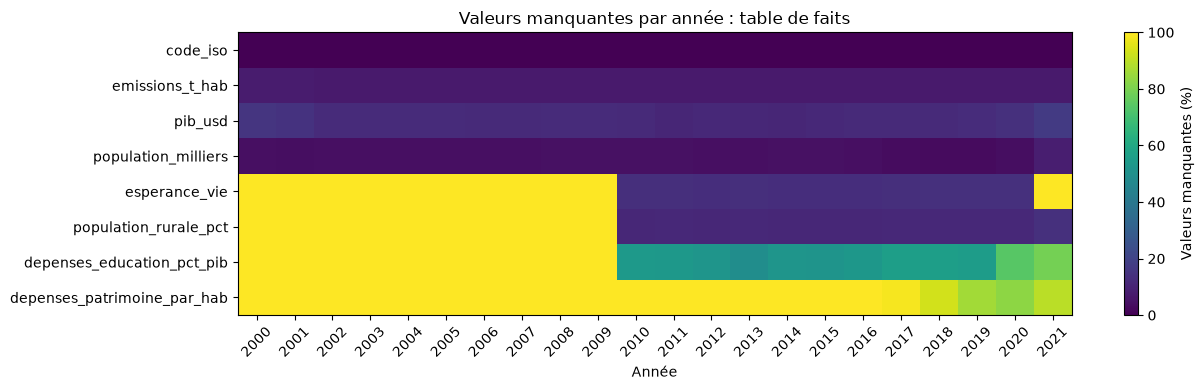

In [98]:
explorer(fait, "table de faits", col_pays="code_iso", col_annee="annee")

In [94]:
# Pour chaque mesure : valeurs dans le fichier d'origine (2000 à 2021) et valeurs dans la table de faits
controle = []
for nom, (table, colonnes) in MESURES.items():
    table = table[table["annee"].between(annee_debut, annee_fin)]
    for colonne in colonnes:
        controle.append({
            "Mesure": colonne,
            "Valeurs dans le fichier": table[colonne].notna().sum(),
            "Valeurs dans la table de faits": fait[colonne].notna().sum(),
        })
controle = pd.DataFrame(controle).set_index("Mesure")
controle["Identique"] = controle["Valeurs dans le fichier"] == controle["Valeurs dans la table de faits"]
display(controle)

,Valeurs dans le fichier,Valeurs dans la table de faits,Identique
Mesure,,,
emissions_t_hab,4808,4808,True
coal,4808,4808,True
oil,4808,4808,True
gas,4808,4808,True
cement,4808,4808,True
flaring,4808,4808,True
pib_usd,4539,4539,True
population_milliers,4958,4958,True
esperance_vie,2245,2245,True


La dépense d'éducation manque sur 77 % des lignes de la table de faits, mais ce taux ne reflète pas son utilité :
il est calculé sur toutes les années depuis 2000, alors que l'indicateur ne commence qu'en 2010 et n'est publié
que par intermittence. De 2010 à 2019, 166 pays ont au moins une année où émissions et dépenses d'éducation
coexistent, et 137 en ont au moins trois. Chaque pays est résumé par la médiane de ces années communes, et seuls
les pays avec au moins trois années sont retenus, pour que la médiane ne repose pas sur une valeur isolée.

### Dimenesion

In [121]:
continents = pd.read_csv(Path("data/reference") / "continents.csv")


In [124]:
# 7.3 Dimension pays

# Un nom par code ISO, pris dans l'ordre de priorité des fichiers
# (le PIB a des noms officiels en anglais ; la population mélange français et anglais, elle passe en dernier)
sources_noms = [
    pd.read_csv(DOSSIER_PROPRE / "pib.csv")[["LOCATION", "Country"]],
    pd.read_csv(DOSSIER_PROPRE / "demographie.csv")[["LOCATION", "Country"]],
    pd.read_csv(DOSSIER_PROPRE / "education.csv")[["LOCATION", "Country"]],
    pd.read_csv(DOSSIER_PROPRE / "patrimoine.csv")[["LOCATION", "Country"]],
    pd.concat([pd.read_csv(DOSSIER_PROPRE / "emissions_pays.csv"),
               pd.read_csv(DOSSIER_PROPRE / "emissions_monde.csv")])[["ISO 3166-1 alpha-3", "Country"]]
    .rename(columns={"ISO 3166-1 alpha-3": "LOCATION"}),
    pd.read_csv(DOSSIER_PROPRE / "population.csv")[["LOCATION", "Country"]],
]
noms = (
    pd.concat(sources_noms)
    .drop_duplicates(subset="LOCATION", keep="first")
    .rename(columns={"LOCATION": "code_iso", "Country": "nom_pays"})
)

# La dimension contient tous les codes ISO de la table de faits
dim_pays = pd.DataFrame({"code_iso": sorted(fait["code_iso"].unique())}).merge(noms, on="code_iso", how="left")

# Continent de chaque code ISO, lu dans un référentiel
continents = pd.read_csv(Path("data/reference") / "continents.csv")
dim_pays = dim_pays.merge(continents, on="code_iso", how="left")
dim_pays.loc[dim_pays["code_iso"] == "WLD", "nom_pays"] = "Monde"

# Type d'entité : la série mondiale est séparée des pays
dim_pays["type_entite"] = dim_pays["code_iso"].map({"WLD": "Monde"}).fillna("Pays")

# Dernière population connue de chaque pays, en milliers, et filtre des pays de plus d'un million d'habitants
derniere_population = (
    fait.dropna(subset=["population_milliers"])
    .sort_values("annee")
    .groupby("code_iso")["population_milliers"].last()
)
dim_pays["population_recente_milliers"] = dim_pays["code_iso"].map(derniere_population)
dim_pays["plus_d_un_million"] = (dim_pays["population_recente_milliers"] > 1000).where(
    dim_pays["population_recente_milliers"].notna()    # population inconnue : le filtre reste vide
)

print(f"Dimension pays : {len(dim_pays)} lignes")
print("Continents :", dim_pays["continent"].value_counts().to_dict())
print("Codes sans continent :", dim_pays.loc[dim_pays["continent"].isna(), "code_iso"].tolist())
print("Codes sans population :", dim_pays.loc[dim_pays["population_recente_milliers"].isna(), "nom_pays"].tolist())
display(dim_pays.head())

Dimension pays : 236 lignes
Continents : {'Afrique': 58, 'Amérique': 54, 'Asie': 51, 'Europe': 49, 'Océanie': 23, 'Monde': 1}
Codes sans continent : []
Codes sans population : ['Andorra', 'Kosovo', 'Lebanon', 'Taiwan', 'Monde']


,code_iso,nom_pays,continent,type_entite,population_recente_milliers,plus_d_un_million
0,ABW,Aruba,Amérique,Pays,107.0,False
1,AFG,Afghanistan,Asie,Pays,39835.0,True
2,AGO,Angola,Afrique,Pays,33934.0,True
3,AIA,Anguilla,Amérique,Pays,15.0,False
4,ALB,Albania,Europe,Pays,2873.0,True


In [123]:
# 7.4 Dimension année : une ligne par année de la table de faits
dim_annee = pd.DataFrame({"annee": range(fait["annee"].min(), fait["annee"].max() + 1)})
dim_annee["decennie"] = "Années " + (dim_annee["annee"] // 10 * 10).astype(str)

print(f"Dimension année : {len(dim_annee)} lignes, de {dim_annee['annee'].min()} à {dim_annee['annee'].max()}")
display(dim_annee["decennie"].value_counts().sort_index().to_frame("Nombre d'années"))

Dimension année : 22 lignes, de 2000 à 2021


,Nombre d'années
decennie,
Années 2000,10
Années 2010,10
Années 2020,2


In [125]:
regles = {
    "Clé de la dimension pays unique": not dim_pays["code_iso"].duplicated().any(),
    "Clé de la dimension année unique": not dim_annee["annee"].duplicated().any(),
    "Clé de la table de faits unique (code ISO + année)": not fait.duplicated(CLES).any(),
    "Chaque code ISO de la table de faits existe dans la dimension pays": fait["code_iso"].isin(dim_pays["code_iso"]).all(),
    "Chaque année de la table de faits existe dans la dimension année": fait["annee"].isin(dim_annee["annee"]).all(),
    "Chaque pays a un nom et un continent": dim_pays[["nom_pays", "continent"]].notna().all().all(),
    "Aucune ligne de faits sans mesure": not fait.drop(columns=CLES).isna().all(axis=1).any(),
}
resultat = pd.Series({regle: "OK" if valide else "KO" for regle, valide in regles.items()}, name="Résultat")
display(resultat.to_frame())

echecs = resultat[resultat == "KO"].index.tolist()
assert not echecs, f"Règles non respectées : {echecs}"
print(f"Les {len(regles)} règles du modèle sont respectées.")

,Résultat
Clé de la dimension pays unique,OK
Clé de la dimension année unique,OK
Clé de la table de faits unique (code ISO + année),OK
Chaque code ISO de la table de faits existe dans la dimension pays,OK
Chaque année de la table de faits existe dans la dimension année,OK
Chaque pays a un nom et un continent,OK
Aucune ligne de faits sans mesure,OK


Les 7 règles du modèle sont respectées.


Le modèle est cohérent : les clés des trois tables sont uniques, chaque code ISO et chaque année de la table de faits
existent dans les dimensions, chaque pays a un nom et un continent, et aucune ligne de faits n'est vide.
Les trois tables sont prêtes à être importées dans Power BI pour répondre aux questions de l'énoncé.